# Chest X ray project: final midterm notebook

Run this notebook once from top to bottom (Runtime, then Run all) with a GPU. Every result appears inside the notebook, and nothing needs to be downloaded or sent back. Our best guess for the whole run is 50 to 70 minutes. If any cell fails with a GPU memory error, use Runtime, then Restart session, and run everything again, because the GPU stays broken after that error.

**What we learned before this notebook, and what it applies**

1. The dataset is a collection of several datasets. According to its own page, normal and pneumonia images are sourced from two Kaggle collections: Pediatric pneumonia and NIH chest X ray. Covid images are sourced from several other sources, including 912 augmented images. Those collections appear as various file types and sizes in our files.
2. A model that doesn't have access to the picture gets about 95 percent, and the typical three class accuracy is largely about the collection, not the disease.
3. VGG16 does better with the pixel scaling it was trained with, so that is now the default. The old scaling stays in as one row, so we can compare with previous runs.
4. Near copies (now also mirrored ones) and images of the same patient (when the file name indicates it) always remain on the same side of a split.
5. Normal against pneumonia in one collection, training in one collection and testing in the other. The second test is our version of the outside hospital test in the Bassi and Attux paper.

**The ten versions**

| Version | Network | Picture | Pixel scaling |
|---|---|---|---|
| VGG16 full, old scaling | VGG16 (parent paper) | Full image | Divide by 255, like our earlier runs |
| VGG16 full | VGG16 | Full image | VGG16's own scaling |
| VGG16 lungs only | VGG16 | Image times the lung map | VGG16's own |
| VGG16 outside only | VGG16 | Lungs blacked out | VGG16's own |
| VGG16 lung crop | VGG16 | Box around both lungs | VGG16's own |
| VGG16 full contrast | VGG16 | Full image after contrast equalization (CLAHE) | VGG16's own |
| VGG19 full | VGG19 (parent paper) | Full image | VGG19's own |
| InceptionV3 full | InceptionV3 (second paper) | Full image | InceptionV3's own |
| DenseNet201 full | DenseNet201 (third paper) | Full image | DenseNet's own |
| DenseNet201 lungs only | DenseNet201 | Image times the lung map, like the third paper | DenseNet's own |

All networks are frozen and only the small classifier on top is trained (Dense 64, Dropout 0.5, Dense output, 12 epochs, best validation epoch kept).

In [1]:
# Cleans everything so every run starts fresh. The dataset zip file is kept to save a 2 minute download.
%cd /content
!rm -rf covid_pneumonia_dataset
!rm -rf covid_pneumonia_dataset_wrapped
!rm -rf pyimagesearch-covid19-image-classification
!rm -rf lung_data
!rm -rf lung_quick
!rm -rf lung_test
!rm -rf lab_cache
!rm -f fast_lab.py
!rm -f results.zip run_*_results.zip paper3_pictures.zip
#!rm -f covid_pneumonia_dataset.zip

/content


In [2]:
# Get the lung finder and helper code from GitHub (or update it if it is already here)
%cd /content
REPO = "/content/pyimagesearch-covid19-image-classification"
import os
if os.path.exists(f"{REPO}/.git"):
    !git -C {REPO} pull
else:
    !git clone https://github.com/MarzSaod/pyimagesearch-covid19-image-classification
%cd /content

/content
Cloning into 'pyimagesearch-covid19-image-classification'...
remote: Enumerating objects: 517, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 517 (delta 37), reused 17 (delta 6), pack-reused 449 (from 1)
Receiving objects: 100% (517/517), 789.73 MiB | 16.11 MiB/s, done.
Resolving deltas: 100% (80/80), done.
Updating files: 100% (395/395), done.
/content


In [3]:
# Downloads the dataset and unzips it into a fresh folder every time, so running this cell twice cannot double the images
%cd /content
import os, shutil, zipfile

mendeley_link = "https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2"
ZIP = "covid_pneumonia_dataset.zip"

if os.path.exists(ZIP) and zipfile.is_zipfile(ZIP):
    print("The zip file is already here, so the download is skipped.")
else:
    !wget -O {ZIP} "$mendeley_link"

shutil.rmtree("covid_pneumonia_dataset", ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("covid_pneumonia_dataset")

for item in os.listdir("covid_pneumonia_dataset"):
    if item.endswith(".zip"):
        inner_path = os.path.join("covid_pneumonia_dataset", item)
        print(f"Found the dataset inside: {item}")
        with zipfile.ZipFile(inner_path) as inner_z:
            print(f"contains {len(inner_z.namelist())} items")
            inner_z.extractall("covid_pneumonia_dataset")
        os.remove(inner_path)

/content
--2026-10-25 19:09:40--  https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/mxc6vb7svm-2.zip?X-Amz-Security-Token=IQoJb3JpZ2luX2VjEPv%2F%2F%2F%2F%2F%2F%2F%2F%2F%2FwEaCWV1LXdlc3QtMSJIMEYCIQCaUxEPTc4yeK6LQV%2FNoJyRcUv1DhwvPQipqNY%2F%2BzSuyQIhANda5YBMrqFQDVCN1KJZ8WmWla0PIuYGXkBQUjkOSGjGKpUFCMP%2F%2F%2F%2F%2F%2F%2F%2F%2F%2FwEQBBoMMzY3MTQ3MzgzODI1Igzmysa7nPsDjAPyj%2Bcq6QRZ8rIYvTUe2LXtVRoVLSDyppeqikyyUQQbaa3OovcQGQ6aOCi6blNdCYFT6O8lF0%2FKNanl5FpAorCYwr1TuOmpypIzAc93kMKGM0ZFCtxr9t6%2BQNSQi2TOpPEUOktxjNzR%2B3zeI9S0aCwlBAMj5eoZd6vOapHiW1xbStL%2F5TjkNx8buugamXRhysxX%2BAPL7N922WC5jmmqzkU2saMZbUTCFmpQjlYwJo2jw9VdnGKDaJLTvguZkIIT%2B7C7fBUFUmYlc00pBn3WQqMLJec0MAHSp5Gvj2ClWViUo4VPJokaHg8%2

In [4]:
# Makes a fresh copy of the dataset in the folder layout the code expects, so running it again never nests a folder inside itself.
import shutil

wrapped_root = "/content/covid_pneumonia_dataset_wrapped/all"
shutil.rmtree(wrapped_root, ignore_errors=True)
os.makedirs(wrapped_root)

for cls in ["covid", "normal", "pneumonia"]:
    src = f"/content/covid_pneumonia_dataset/{cls}"
    dst = f"{wrapped_root}/{cls}"
    assert os.path.exists(src), f"{src} is missing. Run the download cell above first."
    shutil.copytree(src, dst)

print("Data is ready at:", wrapped_root)

Data is ready at: /content/covid_pneumonia_dataset_wrapped/all


In [5]:
# Checks that a GPU is available, because the lung finder and VGG16 are slow without one
import torch
print("PyTorch sees a GPU:", torch.cuda.is_available())
try:
    import tensorflow as tf
    print("TensorFlow sees", len(tf.config.list_physical_devices("GPU")), "GPU")
except Exception as e:
    print("TensorFlow check failed:", e)
if not torch.cuda.is_available():
    print("No GPU found. Use Runtime, then Change runtime type, then pick a GPU, and run everything again.")

PyTorch sees a GPU: True
TensorFlow sees 1 GPU


In [6]:
# Paths and safety checks
import sys, importlib, os
from IPython.display import Image, display

DATASET = "/content/covid_pneumonia_dataset_wrapped/all"
LUNG_DIR = "/content/lung_data"

need = {
    "report_utils.py": "remove_nested_copies",
    "lung_focus.py": "rough guess",
}
for fname, marker in need.items():
    path = f"{REPO}/{fname}"
    assert os.path.exists(path), f"{fname} is missing from your GitHub fork."
    assert marker in open(path).read(), f"Your GitHub copy of {fname} is an old version. Upload the new one to your fork, then run the git cell again."

sys.path.insert(0, REPO)
import report_utils as ru
importlib.reload(ru)
print("Code is up to date.")

Code is up to date.


In [7]:
# Stops here if the dataset folder is wrong, so no time is lost later
removed, kept = ru.remove_nested_copies(DATASET)
classes, files, labels, skipped = ru.list_dataset(DATASET)
counts = {c: int((labels == i).sum()) for i, c in enumerate(classes)}
print("Images per class:", counts, "| total:", len(files), "| skipped files:", dict(skipped))
extra = ru.duplicate_name_count(files, labels)
assert extra == 0, f"{extra} file names appear twice in one class. Run the cleanup and download cells again."
assert all(v == 2313 for v in counts.values()), "The dataset page lists 2313 images per class (6939 in total). Something is different here."
print("Dataset check passed.")

No copied folders found.
Images per class: {'covid': 2313, 'normal': 2313, 'pneumonia': 2313} | total: 6939 | skipped files: {}
Dataset check passed.


In [8]:
%%writefile /content/fast_lab.py
"""
fast_lab.py (final version for the midterm)

The slow part (each network looking at every image) runs once per image version, and the features are kept.
The small classifier on top then trains in about a second, so we can compare many image versions, networks,
splits and seeds in one run. Everything is plain functions, and the notebook shows every result inline.
"""
import os
import re
import time
from concurrent.futures import ThreadPoolExecutor
from types import SimpleNamespace

import cv2
import numpy as np
import pandas as pd

SIZE = 224
WEIGHTS = "imagenet"  # the tests on made up data switch this to None
RNG_FRACS = (0.20, 0.15)  # validation and test fractions, the same as the earlier runs

# Every version: which picture, which pixel scaling, which lung frame, which network.
VARIANTS = {
    "VGG16 full, old scaling": dict(img="full", prep="rescale", frame="full", net="vgg16"),
    "VGG16 full": dict(img="full", prep="vgg", frame="full", net="vgg16"),
    "VGG16 lungs only": dict(img="lungs", prep="vgg", frame="full", net="vgg16"),
    "VGG16 outside only": dict(img="outside", prep="vgg", frame="full", net="vgg16"),
    "VGG16 lung crop": dict(img="crop", prep="vgg", frame="crop", net="vgg16"),
    "VGG16 full contrast": dict(img="full_clahe", prep="vgg", frame="full", net="vgg16"),
    "VGG19 full": dict(img="full", prep="vgg", frame="full", net="vgg19"),
    "InceptionV3 full": dict(img="full", prep="inception", frame="full", net="inceptionv3"),
    "DenseNet201 full": dict(img="full", prep="densenet", frame="full", net="densenet201"),
    "DenseNet201 lungs only": dict(img="lungs", prep="densenet", frame="full", net="densenet201"),
}
BASELINE = "VGG16 full"
OLD = "VGG16 full, old scaling"
SPLIT_NAMES = {"filename": "Filename split", "random": "Random split", "grouped": "Grouped split"}
COLORS = {"filename": "#E69F00", "random": "#0072B2", "grouped": "#009E73"}
SRC_A, SRC_B, SRC_C = "PNG 1024 by 1024", "JPEG other sizes", "Other files"
FILE_ONLY = "File clues only (no picture)"
NET_BATCH = {"densenet201": 8, "inceptionv3": 16}  # small batches for the deep networks, so GPU memory never runs out

_TF = {}


# ---------------------------------------------------------------------------------------------
# Networks
# ---------------------------------------------------------------------------------------------
def setup_tf():
    import tensorflow as tf

    try:
        for g in tf.config.list_physical_devices("GPU"):
            tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:  # already initialised, that is fine
        print("GPU memory setting skipped:", e)
    return tf


def get_base(net="vgg16", size=None):
    """One object per network for the whole run, so features and heatmaps always use the same weights."""
    size = size or SIZE
    key = (net, WEIGHTS, size)
    if key not in _TF:
        from tensorflow.keras import Model, applications, layers

        build = {"vgg16": applications.VGG16, "vgg19": applications.VGG19,
                 "inceptionv3": applications.InceptionV3, "densenet201": applications.DenseNet201}[net]
        base = build(weights=WEIGHTS, include_top=False, input_shape=(size, size, 3))
        feat = Model(base.input, layers.GlobalAveragePooling2D()(base.output))
        _TF[key] = (base, feat)
    return _TF[key]


def prep(x, mode):
    """x is float32 (N, H, W, 3) with values 0 to 255. Each network gets the scaling it was trained with."""
    from tensorflow.keras.applications import densenet, inception_v3, vgg16

    if mode == "vgg":
        return vgg16.preprocess_input(x.copy())
    if mode == "inception":
        return inception_v3.preprocess_input(x.copy())
    if mode == "densenet":
        return densenet.preprocess_input(x.copy())
    return x / 255.0


# ---------------------------------------------------------------------------------------------
# Reading images and building every version of each one
# ---------------------------------------------------------------------------------------------
def read_gray(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if g is None:
        from PIL import Image

        g = np.array(Image.open(path).convert("L"))
    return g


def contrast(gray_u8):
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray_u8)


def lung_box(mask_u8, min_area=0.01):
    """Box around both lungs in the 224 by 224 mask frame. Returns None when the mask is nearly empty."""
    b = (mask_u8 > 127).astype(np.uint8)
    area = float(b.mean())
    if area < min_area:
        return None, area
    n, lab, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    keep = [k + 1 for k, a in enumerate(areas) if a >= 0.15 * areas.max()]
    ys, xs = np.where(np.isin(lab, keep))
    return (int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1), area


def to3(g):
    return np.repeat(g[..., None], 3, axis=2)


def build_one(path, mask, size=None):
    """All image versions for one X ray. mask is the 224 by 224 lung map (0 to 255)."""
    size = size or SIZE
    gray = read_gray(path)
    h, w = gray.shape
    full = cv2.resize(gray, (size, size), interpolation=cv2.INTER_AREA)
    m = mask if size == mask.shape[0] else cv2.resize(mask, (size, size), interpolation=cv2.INTER_LINEAR)
    mf = m.astype(np.float32) / 255.0
    box, area = lung_box(mask)
    fallback = box is None
    if fallback:
        box = (0, 0, mask.shape[1], mask.shape[0])
    x0, y0, x1, y1 = box
    mw, mh = int(0.05 * (x1 - x0)), int(0.05 * (y1 - y0))
    x0, y0 = max(0, x0 - mw), max(0, y0 - mh)
    x1, y1 = min(mask.shape[1], x1 + mw), min(mask.shape[0], y1 + mh)
    gx0, gx1 = int(x0 * w / mask.shape[1]), max(int(x0 * w / mask.shape[1]) + 8, int(x1 * w / mask.shape[1]))
    gy0, gy1 = int(y0 * h / mask.shape[0]), max(int(y0 * h / mask.shape[0]) + 8, int(y1 * h / mask.shape[0]))
    crop = cv2.resize(gray[gy0:gy1, gx0:gx1], (size, size), interpolation=cv2.INTER_AREA)
    mask_crop = cv2.resize(mask[y0:y1, x0:x1], (size, size), interpolation=cv2.INTER_LINEAR)
    imgs = {
        "full": to3(full),
        "lungs": to3((full * mf).astype(np.uint8)),
        "outside": to3((full * (1 - mf)).astype(np.uint8)),
        "crop": to3(crop),
        "full_clahe": to3(contrast(full)),
    }
    info = {
        "h": h, "w": w, "nbytes": os.path.getsize(path), "ext": os.path.splitext(path)[1].lower(),
        "mean_gray": float(full.mean()), "std_gray": float(full.std()),
        "lung_frac": area, "crop_fallback": fallback,
    }
    thumb = cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA)
    return imgs, {"full": m, "crop": mask_crop}, info, thumb


def load_index(dataset, masks_npz):
    """Reads the lung map file and puts every image in sorted order per class, like the earlier filename split."""
    z = np.load(masks_npz)
    rel = [str(r) for r in z["rel"]]
    labels = z["labels"].astype(int)
    classes = [str(c) for c in z["classes"]]
    order = sorted(range(len(rel)), key=lambda i: (labels[i], rel[i]))
    lab = SimpleNamespace()
    lab.classes = classes
    lab.rel = [rel[i] for i in order]
    lab.labels = labels[order]
    lab.masks = np.ascontiguousarray(z["mask"][order])
    lab.paths = []
    for r, c in zip(lab.rel, lab.labels):
        p = os.path.join(dataset, r)
        if not os.path.exists(p) and os.path.exists(r):
            p = r
        if not os.path.exists(p):
            p = os.path.join(dataset, classes[c], os.path.basename(r))
        lab.paths.append(p)
    missing = [p for p in lab.paths if not os.path.exists(p)]
    assert not missing, f"{len(missing)} images from the lung map are missing, for example {missing[0]}"
    return lab


def show_variants(lab, seed=0):
    """One example per class in every picture version, so the reader sees exactly what the networks get."""
    import matplotlib.pyplot as plt

    names = [("full", "Full image"), ("lungs", "Lungs only"), ("outside", "Outside only"), ("crop", "Lung crop"),
             ("full_clahe", "Full contrast")]
    rng = np.random.RandomState(seed)
    pick = [int(rng.choice(np.where(lab.labels == c)[0])) for c in range(len(lab.classes))]
    fig, axes = plt.subplots(len(pick), len(names), figsize=(2.3 * len(names), 2.4 * len(pick)))
    for r, i in enumerate(pick):
        imgs = build_one(lab.paths[i], lab.masks[i])[0]
        for c, (key, title) in enumerate(names):
            ax = axes[r, c]
            ax.imshow(imgs[key][..., 0], cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(title, fontsize=9)
            if c == 0:
                ax.set_ylabel(lab.classes[lab.labels[i]], fontsize=9)
    plt.tight_layout()
    plt.show()


def extract_all(lab, variants=VARIANTS, chunk=32, workers=4, size=None, cache_path=None):
    """Each network looks at every image version once. Images are read once and shared by all networks."""
    size = size or SIZE
    n = len(lab.paths)
    if cache_path and os.path.exists(cache_path):
        z = np.load(cache_path, allow_pickle=True)
        if list(z["rel"]) == lab.rel and list(z["names"]) == list(variants):
            lab.feats = {k: z["f_" + str(i)] for i, k in enumerate(variants)}
            lab.thumbs = z["thumbs"]
            lab.meta = pd.read_pickle(cache_path + ".meta.pkl")
            print("The saved features from this run were found, so the image pass is skipped.")
            return lab
    nets = sorted({v["net"] for v in variants.values()})
    models = {net: get_base(net, size)[1] for net in nets}
    print("Networks loaded:", ", ".join(nets))
    feats = {}
    infos, thumbs = [None] * n, np.zeros((n, 32, 32), np.uint8)
    t0 = time.time()

    def job(i):
        return build_one(lab.paths[i], lab.masks[i], size)

    chunks = [list(range(s, min(n, s + chunk))) for s in range(0, n, chunk)]
    with ThreadPoolExecutor(workers) as ex:
        futs = [[ex.submit(job, i) for i in chunks[0]]]
        for ci, idx in enumerate(chunks):
            if ci + 1 < len(chunks):
                futs.append([ex.submit(job, i) for i in chunks[ci + 1]])
            built = [f.result() for f in futs[ci]]
            futs[ci] = None
            for j, i in enumerate(idx):
                infos[i], thumbs[i] = built[j][2], built[j][3]
            stacks = {}
            for name, spec in variants.items():
                if spec["img"] not in stacks:
                    stacks[spec["img"]] = np.stack([b[0][spec["img"]] for b in built]).astype(np.float32)
                out = models[spec["net"]].predict(prep(stacks[spec["img"]], spec["prep"]),
                                                  batch_size=NET_BATCH.get(spec["net"], 32), verbose=0)
                if name not in feats:
                    feats[name] = np.zeros((n, out.shape[1]), np.float32)
                feats[name][idx] = out
            if ci % 10 == 0 or ci == len(chunks) - 1:
                print(f"  {idx[-1] + 1}/{n} images done, {(time.time() - t0) / 60:.1f} minutes so far", flush=True)
    lab.feats, lab.thumbs, lab.meta = feats, thumbs, pd.DataFrame(infos)
    lab.meta["label"] = lab.labels
    lab.meta["cls"] = [lab.classes[c] for c in lab.labels]
    lab.meta["name"] = [os.path.basename(r) for r in lab.rel]
    if cache_path:
        os.makedirs(os.path.dirname(cache_path), exist_ok=True)
        np.savez(cache_path, rel=np.array(lab.rel), names=np.array(list(variants)), thumbs=thumbs,
                 **{"f_" + str(i): feats[k] for i, k in enumerate(variants)})
        lab.meta.to_pickle(cache_path + ".meta.pkl")
    print(f"Image pass finished in {(time.time() - t0) / 60:.1f} minutes.")
    return lab


# ---------------------------------------------------------------------------------------------
# Where each image came from
# ---------------------------------------------------------------------------------------------
def add_sources(lab):
    m = lab.meta
    big = (m.h == 1024).values & (m.w == 1024).values
    src = np.where((m.ext.values == ".png") & big, SRC_A, np.where((m.ext.values == ".jpeg") & ~big, SRC_B, SRC_C))
    lab.meta["source"] = src
    return lab


def source_table(lab):
    t = pd.crosstab(lab.meta.source, lab.meta.cls)
    return t.loc[[s for s in (SRC_A, SRC_B, SRC_C) if s in t.index]]


def size_table(lab, top=8):
    m = lab.meta.copy()
    m["size"] = m.w.astype(str) + " by " + m.h.astype(str)
    t = pd.crosstab(m["size"], m["cls"])
    t["total"] = t.sum(axis=1)
    return t.sort_values("total", ascending=False).head(top)


def file_type_table(lab):
    return pd.crosstab(lab.meta.ext, lab.meta.cls)


def name_examples(lab, k=3):
    """A few file names per class and source, so we can see how each collection names its files."""
    rows = []
    for (cls, src), g in lab.meta.groupby(["cls", "source"]):
        rows.append({"class": cls, "source": src, "images": len(g), "example names": ", ".join(g.name.head(k))})
    return pd.DataFrame(rows).set_index(["class", "source"])


# ---------------------------------------------------------------------------------------------
# Groups: near copies (including mirrored copies) and same patient where the file name tells us
# ---------------------------------------------------------------------------------------------
PATIENT_PATTERNS = [
    (re.compile(r"^(\d{8})_\d{3}$"), "nih"),                                      # NIH style: 00000001_000
    (re.compile(r"^person(\d+)_(?:bacteria|virus)_\d+$", re.I), "kp"),             # person1_bacteria_1
    (re.compile(r"^((?:normal2-)?im-\d{4})-\d{4}(?:-\d{4})?$", re.I), "kn"),      # IM-0115-0001, NORMAL2-IM-...
]


def patient_keys(names):
    keys = []
    for nm in names:
        stem = os.path.splitext(nm)[0]
        key = ""
        for pat, tag in PATIENT_PATTERNS:
            mt = pat.match(stem)
            if mt:
                key = tag + ":" + mt.group(1).lower()
                break
        keys.append(key)
    return np.array(keys)


def near_copy_edges(thumbs, max_group=None, verbose=True):
    """
    Pairs of images whose 32 by 32 thumbnails correlate at 0.98 or more, also after mirroring one of them.
    Chest X rays look alike, so if one giant group appears the bar is raised until groups are small again.
    """
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(thumbs)
    max_group = max_group or max(20, int(0.005 * n))

    def norm(t):
        x = t.reshape(len(t), -1).astype(np.float32)
        x -= x.mean(1, keepdims=True)
        s = x.std(1, keepdims=True)
        s[s < 1e-6] = 1e6  # blank images match nothing
        return x / s / np.sqrt(x.shape[1])

    x, xf = norm(thumbs), norm(thumbs[:, :, ::-1])
    rows, cols, sims = [], [], []
    for a in range(0, n, 1000):
        c = np.maximum(x[a:a + 1000] @ x.T, x[a:a + 1000] @ xf.T)
        r, k = np.where(c >= 0.98)
        keep = (r + a) < k
        rows.append(r[keep] + a)
        cols.append(k[keep])
        sims.append(c[r[keep], k[keep]])
    rows, cols, sims = np.concatenate(rows), np.concatenate(cols), np.concatenate(sims)
    for bar in (0.98, 0.99, 0.995, 0.998, 0.9995):
        keep = sims >= bar
        g = coo_matrix((np.ones(int(keep.sum())), (rows[keep], cols[keep])), shape=(n, n))
        _, groups = connected_components(g, directed=False)
        biggest = int(np.bincount(groups).max())
        if verbose:
            print(f"  near copy bar {bar}: largest group has {biggest} images")
        if biggest <= max_group:
            break
    return rows[keep], cols[keep]


def make_groups(lab, max_patient_images=60):
    """Joins near copies and same patient images into one group each, so they always land on the same side."""
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(lab.labels)
    r1, c1 = near_copy_edges(lab.thumbs)
    keys = patient_keys(lab.meta.name.values)
    counts = pd.Series(keys[keys != ""]).value_counts()
    too_big = set(counts.index[counts > max_patient_images])
    if too_big:
        print(f"  {len(too_big)} patient keys had more than {max_patient_images} images and were ignored")
        keys = np.array([k if k not in too_big else "" for k in keys])
    r2, c2 = [], []
    for k, idx in pd.Series(np.arange(n))[keys != ""].groupby(keys[keys != ""]):
        idx = idx.values
        if len(idx) > 1:
            r2 += list(idx[:-1])
            c2 += list(idx[1:])
    rows = np.concatenate([r1, np.array(r2, dtype=int)])
    cols = np.concatenate([c1, np.array(c2, dtype=int)])
    g = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    _, groups = connected_components(g, directed=False)
    biggest = int(np.bincount(groups).max())
    print(f"  groups after joining near copies and patients: {groups.max() + 1}, largest has {biggest} images")
    if biggest > max(20, 0.01 * n):
        print("  Warning: one group holds more than 1 percent of the images, so it can only fit in training.")
    near = np.zeros(n, bool)
    near[r1] = True
    near[c1] = True
    lab.groups, lab.patient_key, lab.has_near_copy = groups, keys, near
    return groups


def group_table(lab):
    sizes = pd.Series(lab.groups).map(pd.Series(lab.groups).value_counts()).values
    rows = []
    for c, name in enumerate(lab.classes):
        m = lab.labels == c
        rows.append({"class": name, "images": int(m.sum()),
                     "with a near copy": int(lab.has_near_copy[m].sum()),
                     "with a patient code in the name": int((lab.patient_key[m] != "").sum()),
                     "sharing a group with another image": int((sizes[m] > 1).sum())})
    mixed = sum(1 for _, idx in pd.Series(np.arange(len(lab.groups))).groupby(lab.groups)
                if len(idx) > 1 and len(set(lab.labels[idx.values])) > 1)
    return pd.DataFrame(rows).set_index("class"), int(sizes.max()), mixed


# ---------------------------------------------------------------------------------------------
# Splits
# ---------------------------------------------------------------------------------------------
def split_indices(kind, y, groups, seed, val_frac=RNG_FRACS[0], test_frac=RNG_FRACS[1]):
    """Returns train, validation and test positions inside y. y must be in sorted order per class for the filename split."""
    classes = np.unique(y)
    tr, va, te = [], [], []
    if kind == "grouped":
        rng = np.random.RandomState(seed)
        gl = pd.DataFrame({"g": groups, "y": y})
        major = gl.groupby("g")["y"].agg(lambda s: s.value_counts().idxmax())
        size = gl.groupby("g").size()
        members = pd.Series(np.arange(len(y))).groupby(groups).apply(list)
        for c in classes:
            n_c = int((y == c).sum())
            nv, nt = int(val_frac * n_c), int(test_frac * n_c)
            gids = np.array(major.index[major.values == c])
            rng.shuffle(gids)
            got_te = got_va = 0
            for g in gids:  # a group only goes to test or validation if it fits, so one big group cannot flood them
                if got_te + size[g] <= nt:
                    te += members[g]
                    got_te += size[g]
                elif got_va + size[g] <= nv:
                    va += members[g]
                    got_va += size[g]
                else:
                    tr += members[g]
        return tuple(np.sort(np.array(a, dtype=int)) for a in (tr, va, te))
    for c in classes:
        idx = np.where(y == c)[0]
        n = len(idx)
        nv, nt = int(val_frac * n), int(test_frac * n)
        if kind == "random":
            idx = np.random.RandomState(seed).permutation(idx)
            va += list(idx[:nv])
            te += list(idx[nv:nv + nt])
            tr += list(idx[nv + nt:])
        else:  # filename: first part validation, last part test, exactly like the earlier runs
            va += list(idx[:nv])
            te += list(idx[n - nt:])
            tr += list(idx[nv:n - nt])
    return tuple(np.sort(np.array(a, dtype=int)) for a in (tr, va, te))


def make_splits(lab, seeds, kinds=("filename", "random", "grouped")):
    lab.splits = {}
    for kind in kinds:
        for s in (seeds if kind != "filename" else [0]):
            lab.splits[(kind, s)] = split_indices(kind, lab.labels, lab.groups, s)
    return lab.splits


def split_table(lab, seed=0):
    """How many images of each class sit in each set, and which collection they come from."""
    src = lab.meta.source.values
    rows = []
    for kind in SPLIT_NAMES:
        for part, ix in zip(("train", "validation", "test"), lab.splits[(kind, 0 if kind == "filename" else seed)]):
            row = {"split": SPLIT_NAMES[kind], "set": part, "images": len(ix)}
            for c, name in enumerate(lab.classes):
                row[name] = int((lab.labels[ix] == c).sum())
            for s in (SRC_A, SRC_B):
                row["share " + s] = float((src[ix] == s).mean())
            rows.append(row)
    return pd.DataFrame(rows).set_index(["split", "set"])


# ---------------------------------------------------------------------------------------------
# The small classifier on top of the saved features
# ---------------------------------------------------------------------------------------------
def fit_head(xtr, ytr, xva, yva, xte, n_classes, seed, epochs=12, bs=32, lr=1e-3):
    """Same head as the Keras model: Dense 64, Dropout 0.5, Dense n. Keeps the epoch with the best validation accuracy."""
    import torch
    import torch.nn as nn
    import torch.nn.functional as F

    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    d = xtr.shape[1]
    net = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, n_classes))
    for m in net:
        if isinstance(m, nn.Linear):  # Keras default start values
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)
    opt = torch.optim.Adam(net.parameters(), lr=lr, eps=1e-7)
    xtr_t, ytr_t = torch.from_numpy(xtr), torch.from_numpy(ytr).long()
    xva_t, yva_t = torch.from_numpy(xva), torch.from_numpy(yva).long()
    best, best_ep, best_state = -1.0, 0, None
    n = len(xtr_t)
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(n, generator=gen)
        for s in range(0, n, bs):
            idx = perm[s:s + bs]
            opt.zero_grad(set_to_none=True)
            F.cross_entropy(net(xtr_t[idx]), ytr_t[idx]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            acc = (net(xva_t).argmax(1) == yva_t).float().mean().item()
        if acc > best:
            best, best_ep = acc, ep + 1
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    net.eval()
    with torch.no_grad():
        p_te = torch.softmax(net(torch.from_numpy(xte)), 1).numpy() if len(xte) else np.zeros((0, n_classes))
    return {"val_acc": best, "best_epoch": best_ep, "state": best_state, "p_te": p_te}


def head_probs(state, x):
    import torch
    import torch.nn as nn

    net = nn.Sequential(nn.Linear(x.shape[1], 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, state["3.weight"].shape[0]))
    net.load_state_dict(state)
    net.eval()
    with torch.no_grad():
        return torch.softmax(net(torch.from_numpy(x)), 1).numpy()


def score(y, pred, n_classes):
    rec = []
    for c in range(n_classes):
        m = y == c
        rec.append(float((pred[m] == c).mean()) if m.any() else np.nan)
    return float((pred == y).mean()), rec, float(np.nanmean(rec))


def balanced_pick(y, rng):
    """Repeats images of the smaller classes so every class counts the same. Used for training and for picking the epoch."""
    classes = np.unique(y)
    m = max(int((y == c).sum()) for c in classes)
    out = []
    for c in classes:
        idx = np.where(y == c)[0]
        out.append(idx if len(idx) == m else np.concatenate([idx, rng.choice(idx, m - len(idx), replace=True)]))
    return np.concatenate(out)


def pm(series, pct=True, digits=1):
    series = pd.Series(series).dropna()
    if len(series) == 0:
        return "n/a"
    m, s = series.mean(), series.std(ddof=1) if len(series) > 1 else 0.0
    k = 100 if pct else 1
    return f"{m * k:.{digits}f} ± {s * k:.{digits}f}"


def order_of(names):
    return [v for v in VARIANTS if v in set(names)]


# ---------------------------------------------------------------------------------------------
# Experiment 1: the usual three class task on three kinds of split
# ---------------------------------------------------------------------------------------------
def run_grid(lab, variants=None, seeds=range(5), kinds=("filename", "random", "grouped"), keep=("grouped", 0)):
    variants = list(variants or lab.feats)
    n_cls = len(lab.classes)
    y = lab.labels
    rows, states, preds = [], {}, {}
    t0 = time.time()
    pn, nm = lab.classes.index("pneumonia"), lab.classes.index("normal")
    for v in variants:
        f = lab.feats[v]
        for kind in kinds:
            for s in seeds:
                tr, va, te = lab.splits[(kind, 0 if kind == "filename" else s)]
                r = fit_head(f[tr], y[tr], f[va], y[va], f[te], n_cls, seed=s)
                pred = r["p_te"].argmax(1)
                acc, rec, bal = score(y[te], pred, n_cls)
                row = {"variant": v, "split": kind, "seed": s, "val_acc": r["val_acc"], "test_acc": acc,
                       "balanced": bal, "best_epoch": r["best_epoch"]}
                for c, name in enumerate(lab.classes):
                    row["rec_" + name] = rec[c]
                mp = y[te] == pn
                row["pneu_to_normal"] = float((pred[mp] == nm).mean()) if mp.any() else np.nan
                rows.append(row)
                preds[(v, kind, s)] = pred
                if (kind, s) == keep:
                    states[v] = r["state"]
        print(f"  {v}: done, {(time.time() - t0):.0f} seconds so far", flush=True)
    return pd.DataFrame(rows), states, preds


def summary_table(grid, metric="test_acc", pct=True, digits=1):
    t = grid.groupby(["variant", "split"])[metric].apply(lambda s: pm(s, pct, digits)).unstack("split")
    cols = [k for k in SPLIT_NAMES if k in t.columns]
    return t[cols].rename(columns=SPLIT_NAMES).loc[order_of(t.index)]


def paired_vs_baseline(grid, metric="test_acc", baseline=BASELINE):
    """Same split and same seed for every version, so the comparison is paired. Differences are in points."""
    out = {}
    for kind in ("random", "grouped"):
        g = grid[grid.split == kind].pivot(index="seed", columns="variant", values=metric)
        d = g.sub(g[baseline], axis=0) * 100
        out[SPLIT_NAMES[kind] + " mean difference"] = d.mean()
        out[SPLIT_NAMES[kind] + " better in seeds"] = (d > 0).sum().astype(int).astype(str) + " of " + str(len(g))
    t = pd.DataFrame(out).drop(index=baseline)
    return t.loc[order_of(t.index)]


def sanity_check(grid, old_val=79.6, old_test=61.8):
    g = grid[(grid.variant == OLD) & (grid.split == "filename")]
    print(f"{OLD}, filename split ({len(g)} seeds): validation {pm(g.val_acc)}, test {pm(g.test_acc)}.")
    print(f"The first end to end Keras run had validation {old_val} and test {old_test}, and the first fast run had 80.7 and 62.8.")


def headline(grid, split="grouped"):
    g = grid[grid.split == split].pivot(index="seed", columns="variant", values="test_acc")
    means = g.mean() * 100
    best = means.idxmax()
    print(f"Highest average test accuracy on the {SPLIT_NAMES[split].lower()}: {best} with {means[best]:.1f} percent.")
    for ref in (BASELINE, OLD):
        if ref != best:
            d = (g[best] - g[ref]) * 100
            print(f"Against {ref} ({means[ref]:.1f} percent) it was better in {(d > 0).sum()} of {len(d)} seeds, by {d.mean():.1f} points on average.")


def per_source_recall(lab, preds, variants=None, kind="grouped", seeds=range(5)):
    """Recall for each class inside each collection, pooled over seeds. This shows where the three class model fails."""
    variants = order_of(variants or lab.feats)
    src = lab.meta.source.values
    cells = [("normal", SRC_A), ("normal", SRC_B), ("pneumonia", SRC_A), ("pneumonia", SRC_B), ("covid", None)]
    rows, counts = [], {}
    for v in variants:
        row = {"variant": v}
        for cls, s in cells:
            c = lab.classes.index(cls)
            hits = []
            for sd in seeds:
                te = lab.splits[(kind, sd)][2]
                p = preds[(v, kind, sd)]
                m = (lab.labels[te] == c) & ((src[te] == s) if s else True)
                hits += list(p[m] == c)
                if v == variants[0]:
                    counts.setdefault((cls, s), []).append(int(m.sum()))
            label = f"{cls} recall" + (f", {s}" if s else "")
            row[label] = float(np.mean(hits)) if hits else np.nan
        rows.append(row)
    t = pd.DataFrame(rows).set_index("variant")
    n = {f"{cls} test images" + (f", {s}" if s else ""): int(np.mean(v)) for (cls, s), v in counts.items()}
    return t, n


def format_baseline(lab, seeds=range(5)):
    """A model that never sees the picture: only size, file type, file weight and overall brightness."""
    from sklearn.tree import DecisionTreeClassifier

    m = lab.meta
    ext = pd.get_dummies(m.ext).astype(float).values
    x = np.column_stack([m.h, m.w, np.log(m.nbytes), ext, m.mean_gray, m.std_gray])
    rows = []
    y = lab.labels
    for kind in ("random", "grouped"):
        for s in seeds:
            tr, va, te = lab.splits[(kind, s)]
            pred = DecisionTreeClassifier(max_depth=6, random_state=s).fit(x[tr], y[tr]).predict(x[te])
            acc, rec, bal = score(y[te], pred, len(lab.classes))
            rows.append({"split": SPLIT_NAMES[kind], "acc": acc, "pneu": rec[lab.classes.index("pneumonia")]})
    d = pd.DataFrame(rows)
    out = d.groupby("split").agg(**{"Test accuracy": ("acc", lambda s: pm(s)), "Pneumonia recall": ("pneu", lambda s: pm(s))})
    out.attrs["raw"] = d
    return out


def cue_ablation(lab, seeds=range(5), names=("covid", "normal")):
    """Covid against normal on 1024 by 1024 images, with a small tree that only gets one kind of clue."""
    from sklearn.metrics import roc_auc_score
    from sklearn.tree import DecisionTreeClassifier

    m = lab.meta
    big = (m.h == 1024).values & (m.w == 1024).values
    cidx = [lab.classes.index(c) for c in names]
    pos = np.where(big & np.isin(lab.labels, cidx))[0]
    yb = np.array([cidx.index(c) for c in lab.labels[pos]])
    ext = pd.get_dummies(m.ext).astype(float).values
    sets = {
        "File type only": ext,
        "File weight only": np.log(m.nbytes.values)[:, None],
        "Brightness only (average and spread of gray)": np.column_stack([m.mean_gray, m.std_gray]),
    }
    rows = []
    for name, x in sets.items():
        for s in seeds:
            tr, va, te = split_indices("grouped", yb, lab.groups[pos], s)
            clf = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=s).fit(x[pos][tr], yb[tr])
            prob = clf.predict_proba(x[pos][te])[:, 1]
            rows.append({"clue": name, "AUC": roc_auc_score(yb[te], prob)})
    d = pd.DataFrame(rows)
    return d.groupby("clue").agg(**{"AUC": ("AUC", lambda s: pm(s, False, 3))}).loc[list(sets)]


def source_from_pixels(lab, variant=BASELINE, seeds=range(5), min_count=50):
    """
    Inside one class, can the picture alone tell which collection an image came from? The network only sees the
    picture after it is resized to 224 by 224, so a high AUC means the pixels carry a visible source signature.
    """
    from sklearn.metrics import roc_auc_score

    src = lab.meta.source.values
    rows = []
    for name in ("normal", "pneumonia"):
        c = lab.classes.index(name)
        pos = np.where((lab.labels == c) & np.isin(src, [SRC_A, SRC_B]))[0]
        yb = (src[pos] == SRC_A).astype(int)
        if min(int(yb.sum()), int((1 - yb).sum())) < min_count:
            continue
        aucs = []
        for s in seeds:
            tr, va, te = split_indices("grouped", yb, lab.groups[pos], s)
            rng = np.random.RandomState(s)
            trb, vab = tr[balanced_pick(yb[tr], rng)], va[balanced_pick(yb[va], rng)]
            f = lab.feats[variant][pos]
            r = fit_head(f[trb], yb[trb], f[vab], yb[vab], f[te], 2, seed=s)
            if len(set(yb[te])) == 2:
                aucs.append(roc_auc_score(yb[te], r["p_te"][:, 1]))
        rows.append({"class": name, "images " + SRC_A: int(yb.sum()), "images " + SRC_B: int((1 - yb).sum()),
                     "AUC for telling the two collections apart": pm(aucs, False, 3)})
    cols = ["class", "images " + SRC_A, "images " + SRC_B, "AUC for telling the two collections apart"]
    if not rows:
        print("Not enough images in both collections, so this check is skipped.")
    return pd.DataFrame(rows, columns=cols).set_index("class")


# ---------------------------------------------------------------------------------------------
# Experiment 2: normal against pneumonia inside one collection, and across collections
# ---------------------------------------------------------------------------------------------
TASKS = ["Within " + SRC_A, "Within " + SRC_B, "Train " + SRC_B + ", test " + SRC_A, "Train " + SRC_A + ", test " + SRC_B]


def source_tests(lab, variants=None, seeds=range(10), keep_seed=0, keep_variants=("VGG16 full", "VGG16 lung crop")):
    """
    Normal against pneumonia where the collection cannot give the answer away. Inside one collection both classes
    come from the same place. Across collections, the model learns in one place and is tested in the other, like
    the outside hospital test in the Bassi and Attux paper. Classes are balanced by repeating images, groups stay
    together, and the scores are AUC and average recall (chance is 0.5 and 50 percent).
    """
    from sklearn.metrics import roc_auc_score
    from sklearn.tree import DecisionTreeClassifier

    variants = order_of(variants or lab.feats)
    nm, pn = lab.classes.index("normal"), lab.classes.index("pneumonia")
    src = lab.meta.source.values
    m = lab.meta
    file_x = np.column_stack([m.h, m.w, np.log(m.nbytes), m.mean_gray, m.std_gray])
    pos = {s: np.where(np.isin(lab.labels, [nm, pn]) & (src == s))[0] for s in (SRC_A, SRC_B)}
    ys = {s: (lab.labels[pos[s]] == pn).astype(int) for s in pos}
    plan = [(TASKS[0], SRC_A, None), (TASKS[1], SRC_B, None), (TASKS[2], SRC_B, SRC_A), (TASKS[3], SRC_A, SRC_B)]
    rows, kept, counts = [], {}, {}
    t0 = time.time()
    for tname, s_train, s_test in plan:
        p, y = pos[s_train], ys[s_train]
        for sd in seeds:
            if s_test is None:
                tr, va, te = split_indices("grouped", y, lab.groups[p], sd)
                test_pos, y_test = p[te], y[te]
            else:
                tr, va, _ = split_indices("grouped", y, lab.groups[p], sd, test_frac=0.0)
                test_pos, y_test = pos[s_test], ys[s_test]
            if sd == seeds[0]:
                counts[tname] = {"train normal": int((y[tr] == 0).sum()), "train pneumonia": int((y[tr] == 1).sum()),
                                 "test normal": int((y_test == 0).sum()), "test pneumonia": int((y_test == 1).sum())}
            rng = np.random.RandomState(sd)
            trb, vab = p[tr][balanced_pick(y[tr], rng)], p[va][balanced_pick(y[va], rng)]
            ytrb, yvab = lab.labels[trb] == pn, lab.labels[vab] == pn
            for v in variants:
                f = lab.feats[v]
                r = fit_head(f[trb], ytrb.astype(int), f[vab], yvab.astype(int), f[test_pos], 2, seed=sd)
                prob = r["p_te"][:, 1]
                acc, rec, bal = score(y_test, (prob > 0.5).astype(int), 2)
                rows.append({"task": tname, "inputs": v, "seed": sd, "auc": roc_auc_score(y_test, prob), "balanced": bal,
                             "normal recall": rec[0], "pneumonia recall": rec[1]})
                if sd == keep_seed and v in keep_variants:
                    kept[(tname, v)] = (r["state"], test_pos, y_test)
            if s_test is None:
                clf = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=sd)
                clf.fit(file_x[p[tr]], y[tr])
                prob = clf.predict_proba(file_x[test_pos])[:, 1]
                acc, rec, bal = score(y_test, (prob > 0.5).astype(int), 2)
                rows.append({"task": tname, "inputs": FILE_ONLY, "seed": sd, "auc": roc_auc_score(y_test, prob),
                             "balanced": bal, "normal recall": rec[0], "pneumonia recall": rec[1]})
        print(f"  {tname}: done, {(time.time() - t0):.0f} seconds so far", flush=True)
    out = pd.DataFrame(rows)
    out.attrs["counts"], out.attrs["kept"] = counts, kept
    return out


def source_tests_table(st, metric="auc"):
    pct, dg = (False, 3) if metric == "auc" else (True, 1)
    t = st.groupby(["inputs", "task"])[metric].apply(lambda s: pm(s, pct, dg)).unstack("task")
    rows = order_of(t.index) + ([FILE_ONLY] if FILE_ONLY in t.index else [])
    return t.loc[rows, [c for c in TASKS if c in t.columns]].fillna("")


def plot_source_tests(st):
    import matplotlib.pyplot as plt

    order = order_of(st.inputs) + [FILE_ONLY]
    tasks = [t for t in TASKS if t in set(st.task)]
    cols = ["#0072B2", "#009E73", "#E69F00", "#D55E00"]
    fig, ax = plt.subplots(figsize=(8.5, 0.75 * len(order) + 2.2))
    h = 0.8 / len(tasks)
    for k, t in enumerate(tasks):
        g = st[st.task == t].groupby("inputs")["auc"]
        mean, sd = g.mean().reindex(order), g.std().reindex(order).fillna(0)
        y = np.arange(len(order)) + (k - (len(tasks) - 1) / 2) * h
        ax.barh(y, mean, height=h * 0.92, xerr=sd, color=cols[k % 4], label=t, error_kw={"elinewidth": 1, "capsize": 2})
    ax.axvline(0.5, color="#555", lw=1, ls="--")
    ax.text(0.505, -0.6, "chance", fontsize=8, color="#555")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)
    ax.invert_yaxis()
    ax.set_xlim(0.3, 1.0)
    ax.set_xlabel("AUC for normal against pneumonia on held out images")
    ax.set_title("Normal against pneumonia when the collection cannot give the answer away", fontsize=11)
    ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------------------------
# Heatmaps (VGG16 versions only, from the last convolution layer)
# ---------------------------------------------------------------------------------------------
def keras_from_state(state, n_classes, net="vgg16", size=None):
    from tensorflow.keras import Model, layers

    base, _ = get_base(net, size)
    x = layers.GlobalAveragePooling2D()(base.output)
    d1, d2 = layers.Dense(64, activation="relu"), layers.Dense(n_classes, activation="softmax")
    out = d2(layers.Dropout(0.5)(d1(x)))
    d1.set_weights([state["0.weight"].numpy().T, state["0.bias"].numpy()])
    d2.set_weights([state["3.weight"].numpy().T, state["3.bias"].numpy()])
    model = Model(base.input, out)
    grad_model = Model(base.input, [base.get_layer("block5_conv3").output, out])
    return model, grad_model


def check_transfer(lab, states, variant=BASELINE, n=6):
    """The heatmap model must give the same answers as the fast head. Prints the largest difference."""
    idx = np.arange(0, len(lab.labels), max(1, len(lab.labels) // n))[:n]
    spec = VARIANTS[variant]
    x = np.stack([build_one(lab.paths[i], lab.masks[i])[0][spec["img"]] for i in idx]).astype(np.float32)
    model, _ = keras_from_state(states[variant], len(lab.classes), spec["net"])
    p_keras = model(prep(x, spec["prep"]), training=False).numpy()
    p_fast = head_probs(states[variant], lab.feats[variant][idx])
    diff = float(np.abs(p_keras - p_fast).max())
    print(f"Largest difference between the heatmap model and the fast head on {len(idx)} images: {diff:.2e}")
    return diff


def cams_for(grad_model, x, n_classes, bs=16):
    import tensorflow as tf

    cams, pred, conf = [], [], []
    for s in range(0, len(x), bs):
        xb = tf.convert_to_tensor(x[s:s + bs])
        with tf.GradientTape() as tape:
            tape.watch(xb)
            conv, probs = grad_model(xb, training=False)
            cls = tf.argmax(probs, axis=1)
            score_ = tf.reduce_sum(probs * tf.one_hot(cls, n_classes), axis=1)
        grads = tape.gradient(score_, conv)
        w = tf.reduce_mean(grads, axis=(1, 2))
        cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1)).numpy()
        for c in cam:
            c = cv2.resize(c, (x.shape[2], x.shape[1]), interpolation=cv2.INTER_LINEAR)
            cams.append(c / (c.max() + 1e-8))
        pred += list(cls.numpy())
        conf += list(probs.numpy().max(1))
    return np.array(cams), np.array(pred), np.array(conf)


def pick_per_class(idx, y, per_class, seed=0):
    rng = np.random.RandomState(seed)
    chosen, ys = [], []
    for c in np.unique(y):
        pool = idx[y == c]
        take = rng.choice(len(pool), min(per_class, len(pool)), replace=False)
        chosen += list(pool[take])
        ys += [c] * len(take)
    return np.array(chosen), np.array(ys)


def attention_for(lab, states, variants, idx, y_true, class_names, built=None, model_label=""):
    """Share of each heatmap that lands inside the lung map, for the given held out images."""
    built = built or {}
    for i in idx:
        if i not in built:
            built[i] = build_one(lab.paths[i], lab.masks[i])
    rows, store = [], {}
    for v in variants:
        spec = VARIANTS[v]
        x = np.stack([built[i][0][spec["img"]] for i in idx]).astype(np.float32)
        _, gm = keras_from_state(states[v], len(class_names), spec["net"])
        cams, pred, conf = cams_for(gm, prep(x, spec["prep"]), len(class_names))
        store[v] = (cams, pred, conf)
        for j, i in enumerate(idx):
            inside = built[i][1][spec["frame"]] > 127
            tot = cams[j].sum()
            rows.append({"model": model_label, "variant": v, "cls": class_names[y_true[j]],
                         "lung_area": float(inside.mean()),
                         "share": float((cams[j] * inside).sum() / tot) if tot > 0 else np.nan,
                         "correct": bool(pred[j] == y_true[j])})
    return pd.DataFrame(rows), built, store


def attention_table(att):
    g = att.groupby(["model", "variant"], sort=False).agg(lung_area=("lung_area", "mean"), share=("share", "mean"),
                                                           images=("share", "size"))
    g["Ratio"] = g.share / g.lung_area
    models = list(dict.fromkeys(att.model))
    order = [(mdl, v) for mdl in models for v in VARIANTS if (mdl, v) in g.index]
    return g.loc[order].rename(columns={"lung_area": "Lungs fill", "share": "Heatmap inside lungs"})


def heatmap_gallery(built, store, idx, y_true, class_names, variants, n_per_class=2, title=None):
    import matplotlib.pyplot as plt

    pick = []
    for c in range(len(class_names)):
        pick += [j for j in range(len(idx)) if y_true[j] == c][:n_per_class]
    fig, axes = plt.subplots(len(pick), len(variants), figsize=(2.4 * len(variants), 2.5 * len(pick)))
    axes = np.atleast_2d(axes)
    if len(variants) == 1:
        axes = axes.T
    for r, j in enumerate(pick):
        i = idx[j]
        for c, v in enumerate(variants):
            spec = VARIANTS[v]
            ax = axes[r, c]
            ax.imshow(built[i][0][spec["img"]][..., 0], cmap="gray", vmin=0, vmax=255)
            ax.imshow(store[v][0][j], cmap="jet", alpha=0.45, vmin=0, vmax=1)
            ax.contour(built[i][1][spec["frame"]] > 127, levels=[0.5], colors="white", linewidths=0.7)
            ax.set_xticks([])
            ax.set_yticks([])
            p = class_names[store[v][1][j]]
            ok = store[v][1][j] == y_true[j]
            ax.set_title(f"{p} {store[v][2][j]:.0%}", fontsize=8, color="#1b7f3b" if ok else "#b3261e")
            if c == 0:
                ax.set_ylabel(f"true: {class_names[y_true[j]]}", fontsize=8)
            if r == 0:
                ax.text(0.5, 1.25, v, transform=ax.transAxes, ha="center", fontsize=9, fontweight="bold")
    if title:
        print(title)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------------------------
# Charts and the final summary
# ---------------------------------------------------------------------------------------------
def plot_grid(grid, metrics=(("test_acc", "Test accuracy (%)"), ("rec_pneumonia", "Pneumonia recall (%)"))):
    import matplotlib.pyplot as plt

    names = order_of(grid.variant)
    kinds = [k for k in SPLIT_NAMES if k in set(grid.split)]
    fig, axes = plt.subplots(1, len(metrics), figsize=(6.4 * len(metrics), 0.62 * len(names) + 2.2), sharey=True)
    axes = np.atleast_1d(axes)
    h = 0.8 / len(kinds)
    for ax, (m, title) in zip(axes, metrics):
        for k, kind in enumerate(kinds):
            g = grid[grid.split == kind].groupby("variant")[m]
            mean = g.mean().reindex(names) * 100
            sd = g.std().reindex(names).fillna(0) * 100
            y = np.arange(len(names)) + (k - (len(kinds) - 1) / 2) * h
            ax.barh(y, mean, height=h * 0.92, xerr=sd, color=COLORS[kind], label=SPLIT_NAMES[kind],
                    error_kw={"elinewidth": 1, "capsize": 2})
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names)
        ax.set_title(title, fontsize=11)
        ax.set_xlim(0, 100)
        ax.grid(axis="x", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].invert_yaxis()  # shared axis, so it is flipped once
    handles, labels_ = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="upper center", ncol=len(kinds), fontsize=9, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.text(0.5, 0.005, "Bars show the average over seeds and the lines show one standard deviation.", ha="center", fontsize=8)
    plt.tight_layout(rect=(0, 0.03, 1, 0.94))
    plt.show()


def plot_attention(tab):
    import matplotlib.pyplot as plt

    labels_ = [f"{v} ({mdl})" if mdl else v for mdl, v in tab.index]
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(tab) + 1.8))
    y = np.arange(len(tab))
    ax.barh(y, tab["Heatmap inside lungs"] * 100, color="#0072B2", height=0.6, label="Heatmap inside lungs")
    ax.scatter(tab["Lungs fill"] * 100, y, color="#D55E00", zorder=3, s=28, label="Share of the picture the lungs fill")
    ax.set_yticks(y)
    ax.set_yticklabels(labels_)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percent")
    ax.set_title("Where the model looks", fontsize=11)
    ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def final_table(grid, st):
    rows = []
    for v in order_of(grid.variant):
        g, s = grid[grid.variant == v], st[st.inputs == v]
        row = {"Version": v,
               "Three classes, grouped split, accuracy": pm(g[g.split == "grouped"].test_acc)}
        for t in TASKS:
            row["AUC " + t.lower()] = pm(s[s.task == t].auc, False, 3)
        rows.append(row)
    f = st[st.inputs == FILE_ONLY]
    row = {"Version": FILE_ONLY, "Three classes, grouped split, accuracy": ""}
    for t in TASKS:
        row["AUC " + t.lower()] = pm(f[f.task == t].auc, False, 3) if (f.task == t).any() else ""
    rows.append(row)
    return pd.DataFrame(rows).set_index("Version")


def key_numbers(grid, st, fb, psr, att_tab):
    """The numbers for the slides, computed from the results above and written as plain sentences."""
    g = grid[grid.split == "grouped"].pivot(index="seed", columns="variant", values="test_acc") * 100
    means = g.mean()
    best = means.idxmax()
    raw = fb.attrs["raw"]
    tree = raw[raw.split == SPLIT_NAMES["grouped"]].acc.mean() * 100
    print(f"1. A tree that never sees the picture gets {tree:.1f} percent on the three class grouped split.")
    print(f"2. The best network version, {best}, gets {means[best]:.1f} percent on the same split.")
    d = g[BASELINE] - g[OLD]
    print(f"3. Using the scaling VGG16 was trained with changes accuracy by {d.mean():+.1f} points ({(d > 0).sum()} of {len(d)} seeds better).")
    a, b = psr.loc[BASELINE, f"pneumonia recall, {SRC_A}"], psr.loc[BASELINE, f"normal recall, {SRC_B}"]
    print(f"4. {BASELINE} finds {a:.0%} of pneumonia images that come from the PNG collection, "
          f"and calls {b:.0%} of normal images from the JPEG collection normal.")
    for t in TASKS:
        s_ = st[(st.task == t) & (st.inputs != FILE_ONLY)].groupby("inputs").auc.mean()
        f_ = st[(st.task == t) & (st.inputs == FILE_ONLY)].auc
        extra = f", and file clues alone reach {f_.mean():.3f}" if len(f_) else ""
        print(f"5. {t}: AUC ranges from {s_.min():.3f} to {s_.max():.3f} across versions, best is {s_.idxmax()}{extra}.")
    for (mdl, v), row in att_tab.iterrows():
        if v == BASELINE:
            print(f"6. Heatmap of {v} ({mdl}): {row['Heatmap inside lungs']:.0%} inside the lungs, "
                  f"which fill {row['Lungs fill']:.0%} of the picture (ratio {row['Ratio']:.2f}).")

Writing /content/fast_lab.py


## Lung finder

makes a lung map for every X ray, and the pictures below show how well it worked.

In [9]:
%cd {REPO}
!python lung_focus.py --dataset {DATASET} --outdir {LUNG_DIR}
%cd /content

/content/pyimagesearch-covid19-image-classification
[INFO] device: cuda
[INFO] 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] downloading StackedNet.py ...
[INFO] StackedNet.py verified
[INFO] downloading SegmentationDNN.pt ...
[INFO] SegmentationDNN.pt verified
[INFO] lung finder: 96/6939 images, 47.9 images per second, about 2.4 minutes left
[INFO] lung finder: 640/6939 images, 76.6 images per second, about 1.4 minutes left
[INFO] lung finder: 1280/6939 images, 80.6 images per second, about 1.2 minutes left
[INFO] lung finder: 1920/6939 images, 81.8 images per second, about 1.0 minutes left
[INFO] lung finder: 2560/6939 images, 82.4 images per second, about 0.9 minutes left
[INFO] lung finder: 3200/6939 images, 82.7 images per second, about 0.8 minutes left
[INFO] lung finder: 3840/6939 images, 82.8 images per second, about 0.6 minutes left
[INFO] lung finder: 4480/6939 images, 82.8 images per second, about 0.5 minutes left
[INFO] lung finder: 5120/6939 images, 82.

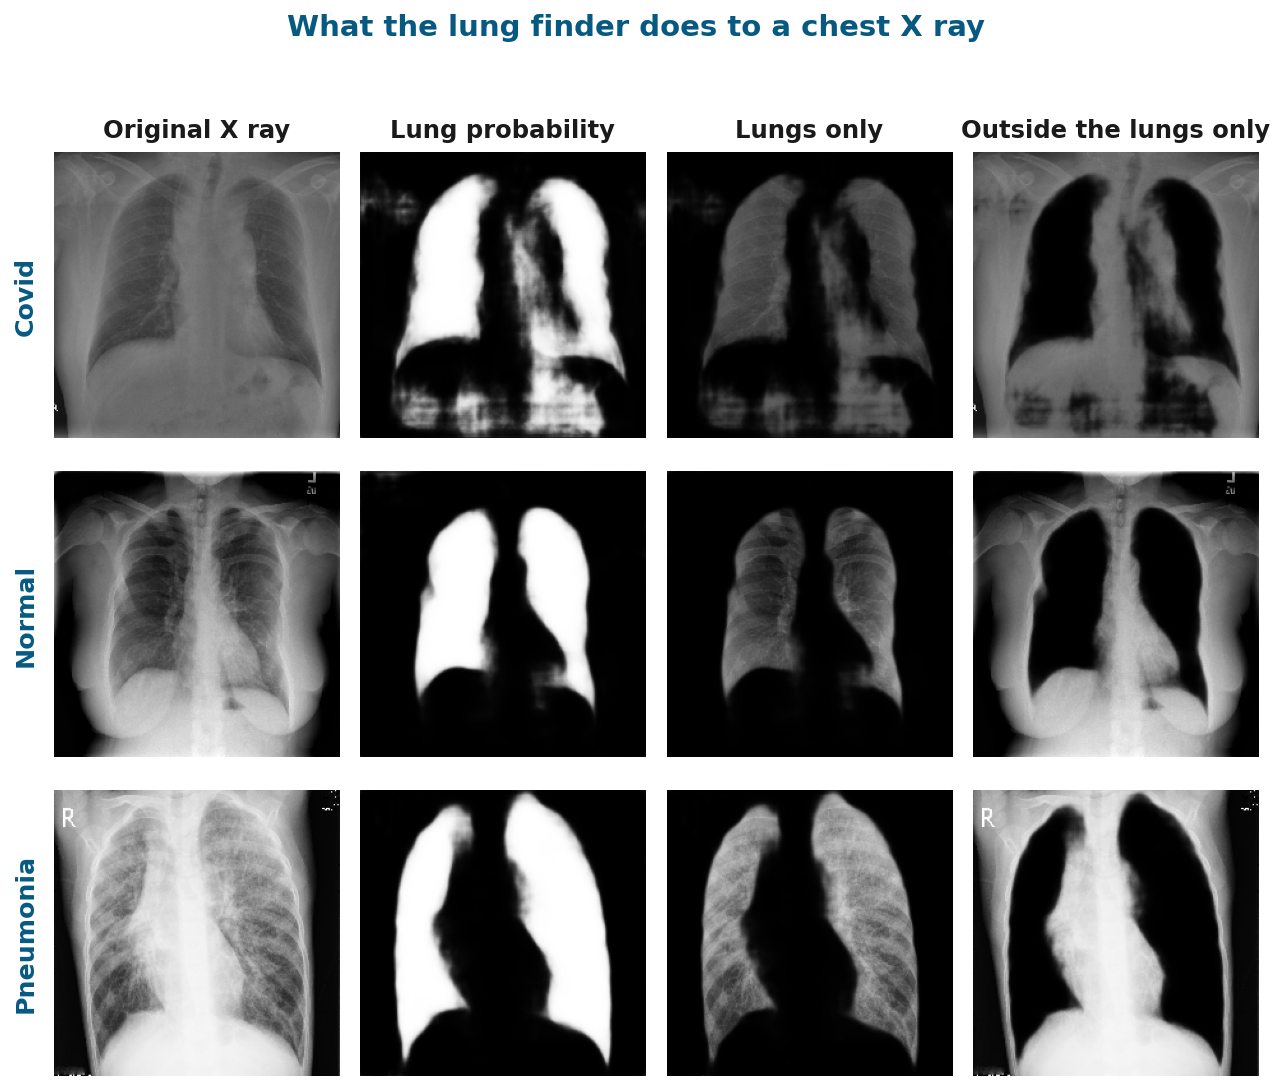

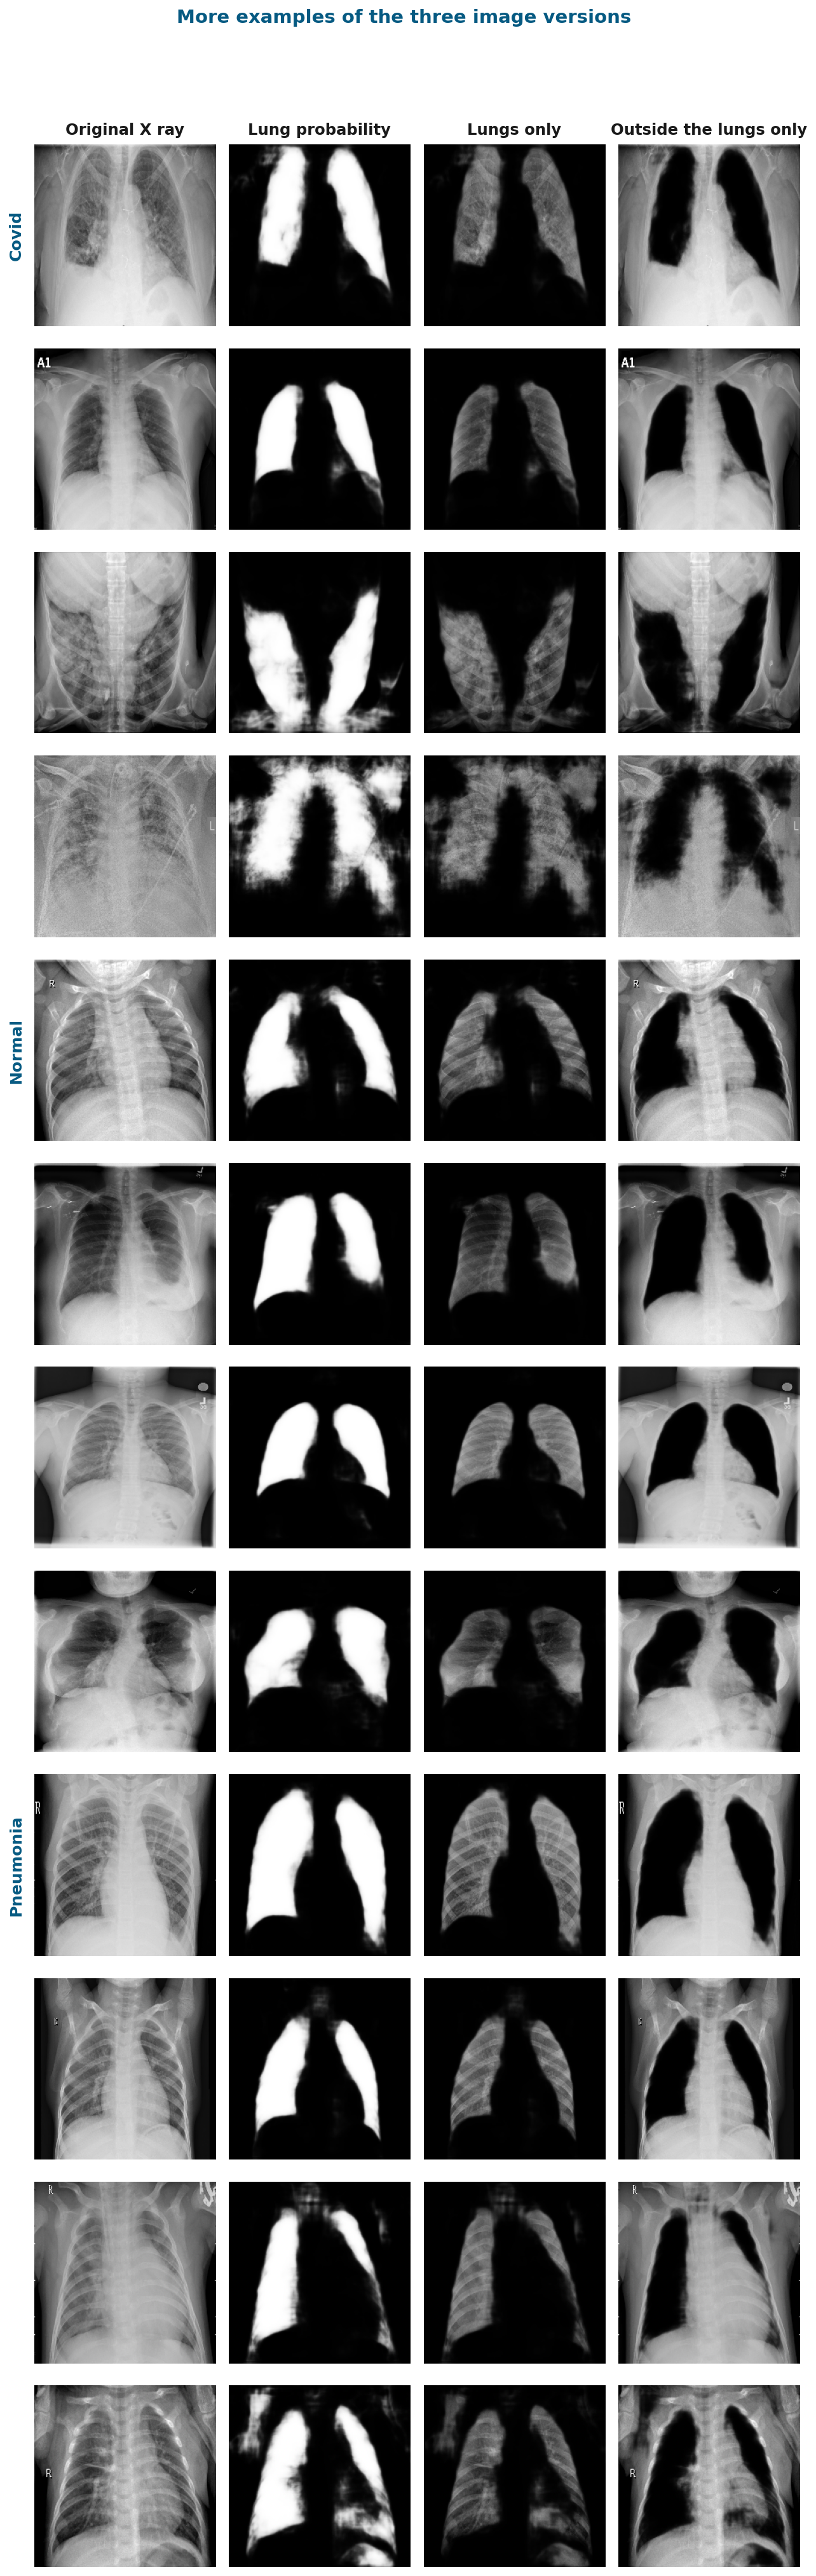

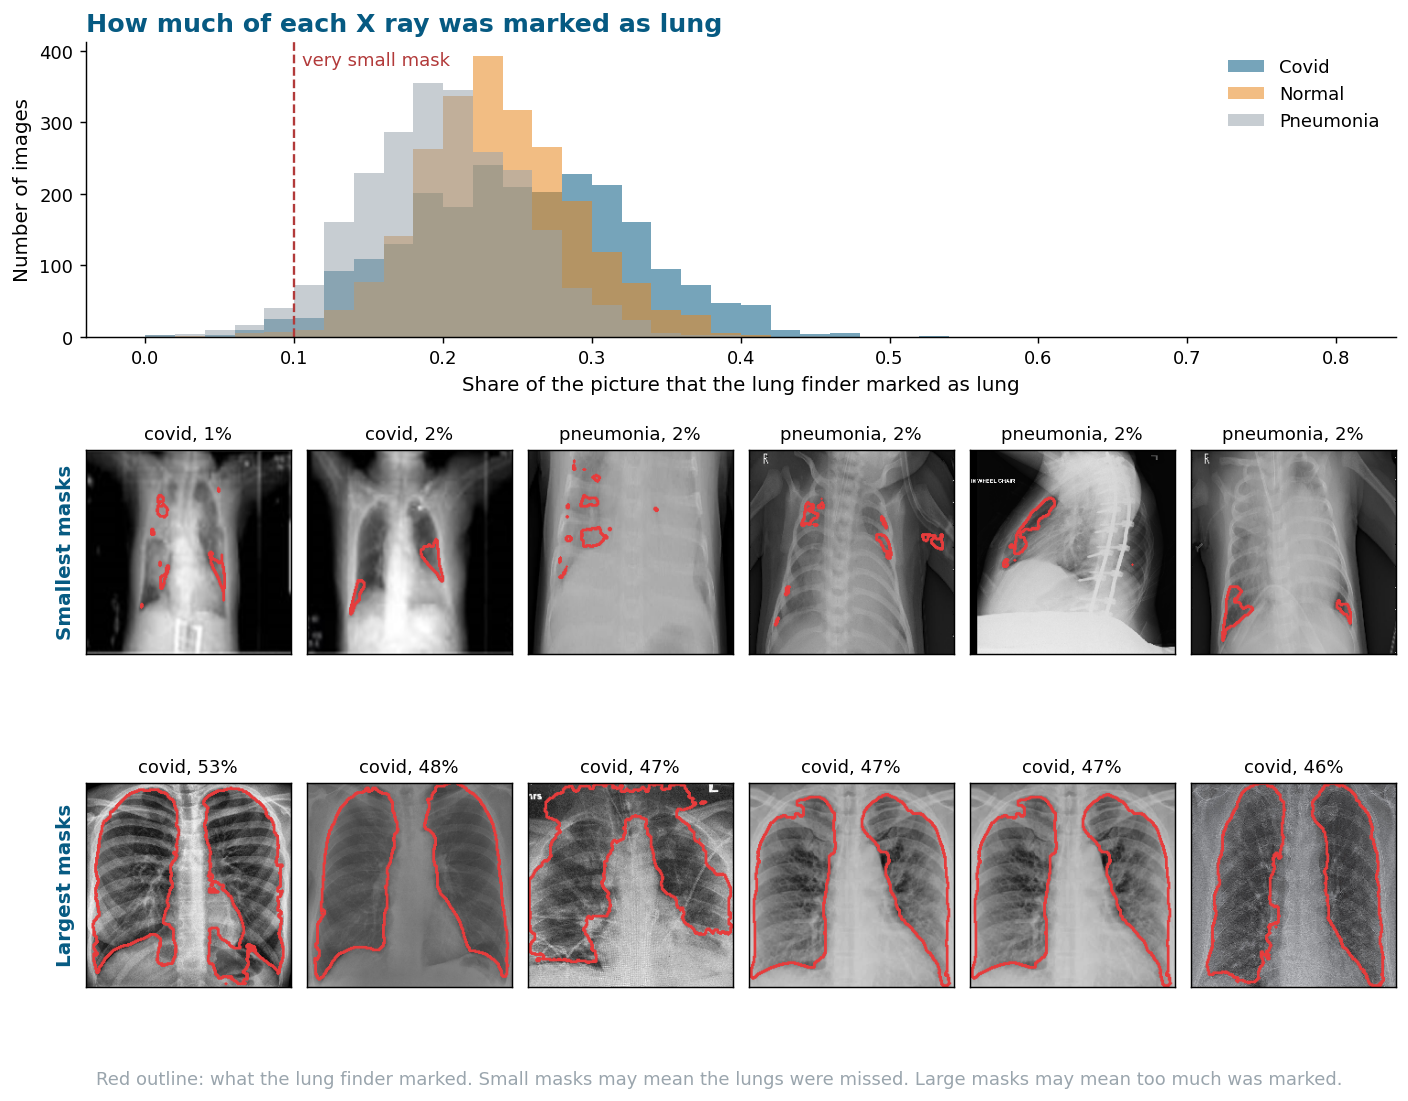

In [10]:
for name in ["lung_focus_preview.png", "lung_focus_more.png", "lung_focus_quality.png"]:
    path = f"{LUNG_DIR}/{name}"
    if os.path.exists(path):
        display(Image(path))
    else:
        print(name, "was not found.")

## What the networks see

One random X ray per class in each picture version.

Images in the lung map: 6939 | classes: ['covid', 'normal', 'pneumonia']


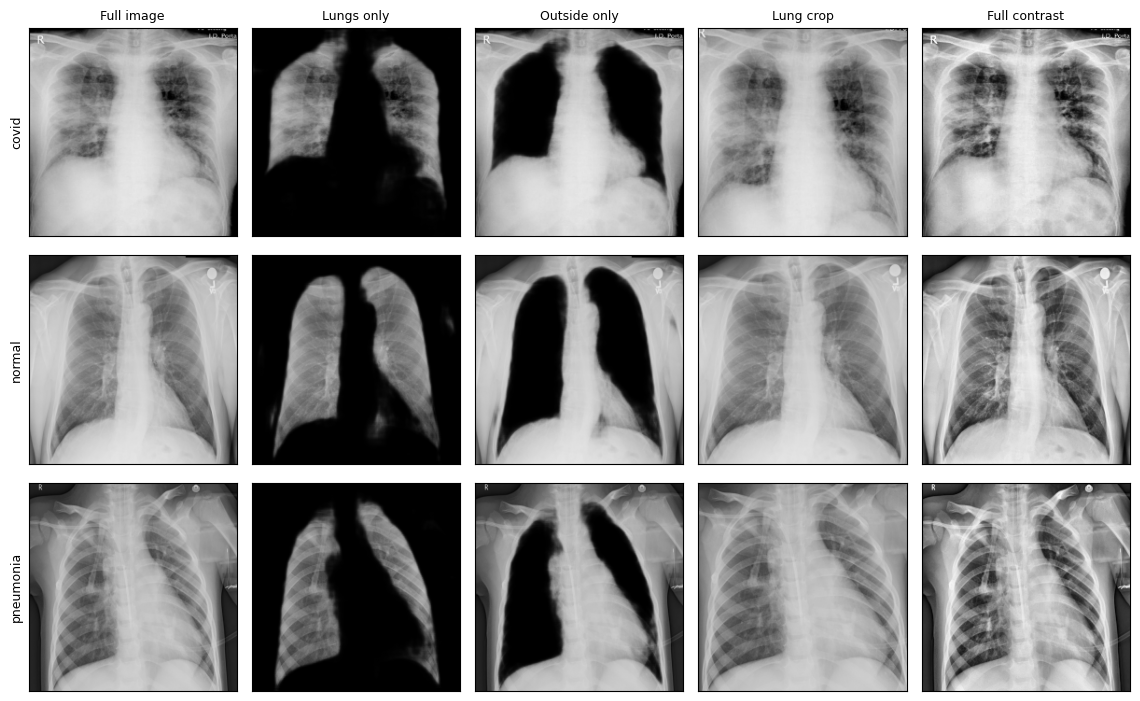

In [11]:
import sys, importlib
import pandas as pd
sys.path.insert(0, "/content")
import fast_lab as fl
importlib.reload(fl)
fl.setup_tf()
pd.set_option("display.max_columns", 30)

SEEDS = range(5)          # repeats for the three class task
SOURCE_SEEDS = range(10)  # repeats for the collection tests, which have small test sets (use range(5) to save about 7 minutes)

lab = fl.load_index(DATASET, f"{LUNG_DIR}/masks.npz")
assert len(lab.rel) == 6939, f"Expected 6939 images, found {len(lab.rel)}."
print("Images in the lung map:", len(lab.rel), "| classes:", lab.classes)
fl.show_variants(lab)

## Image pass

Four networks look at every image in every version once. This is the slowest cell, our guess is 15 to 25 minutes. The deep networks get small batches, so the GPU should not run out of memory. After it, every experiment takes seconds per model.

In [12]:
# Shows which GPU Colab gave us and how much memory is free before the slow part starts
!nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv
lab = fl.extract_all(lab, cache_path="/content/lab_cache/feats.npz")
fl.add_sources(lab)
print("Images where the lung map was almost empty, so the crop uses the whole picture:", int(lab.meta.crop_fallback.sum()))
print("Average share of the picture covered by the lungs:", f"{lab.meta.lung_frac.mean():.0%}")

name, memory.used [MiB], memory.total [MiB]
Tesla T4, 3 MiB, 15360 MiB
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Networks loaded: densenet201, inceptionv3, vgg16, vgg19
  32/6939 images done, 0.8 minutes so far
  352/6939 images done, 1.3 minutes so far
  672/6939 images done, 1.7 minutes so far
  992/6939 images done, 2.2 minutes so far
  1312/6939 images done, 2.6 minutes so far
  1632/6939 images done, 3.1 minutes so far
  1952/6939 images done, 3.6 minutes so far
  2272/6939 images done, 4.1 minutes so far
  2592/6939 images done, 4.6 minutes so far
  2912/6939 images done, 5.1 minutes so far
  3232/6939 images done, 5.6 minutes so far
  3552/6939 images done, 6.0 minutes so far
  3872/6939 images done, 6.5 minutes so far
  4192/6939 images done, 7.0 minutes so far
  4512/6939 images done, 7.5 minutes so far
  4832/6939 im

## Part A: where the images come from

The first table sorts every image into a collection by file type and size. The others show file types, the most common sizes, and a few file names from each group.

In [13]:
print("Images per collection and class:")
display(fl.source_table(lab))
print("File types by class:")
display(fl.file_type_table(lab))
print("Most common image sizes by class:")
display(fl.size_table(lab))
print("Example file names:")
display(fl.name_examples(lab))

Images per collection and class:


cls,covid,normal,pneumonia
source,,,
PNG 1024 by 1024,2,1977,176
JPEG other sizes,181,336,2137
Other files,2130,0,0


File types by class:


cls,covid,normal,pneumonia
ext,,,
.jfif,37,0,0
.jpeg,218,336,2137
.jpg,1725,0,0
.png,333,1977,176


Most common image sizes by class:


cls,covid,normal,pneumonia,total
size,,,,
1024 by 1024,985,1977,176,3138
2000 by 2000,84,0,0,84
1200 by 1200,36,0,0,36
480 by 480,23,0,0,23
3050 by 2539,17,0,0,17
640 by 524,15,0,0,15
1024 by 842,10,0,0,10
640 by 640,9,0,0,9


Example file names:


images  \
class     source                     
covid     JPEG other sizes     181   
          Other files         2130   
          PNG 1024 by 1024       2   
normal    JPEG other sizes     336   
          PNG 1024 by 1024    1977   
pneumonia JPEG other sizes    2137   
          PNG 1024 by 1024     176   

                                                                example names  
class     source                                                               
covid     JPEG other sizes                       001.jpeg, 002.jpeg, 003.jpeg  
          Other files                               007.jpg, 008.jpg, 009.jpg  
          PNG 1024 by 1024                 COVID-19 (1).png, COVID-19 (2).png  
normal    JPEG other sizes  IM-0115-0001.jpeg, IM-0127-0001.jpeg, IM-0131-...  
          PNG 1024 by 1024  00000002_000.png, 00000005_000.png, 00000005_0...  
pneumonia JPEG other sizes  person1000_virus_1681.jpeg, person1002_bacteri...  
          PNG 1024 by 1024  00000165_001.png, 00000218_001.png, 00000499_0...

**Groups and splits.** Near copies (including mirrored ones) and images of the same patient are joined into groups. The grouped split keeps every group on one side. The last two columns of the split table show which collection the images in each set come from.

In [14]:
fl.make_groups(lab)
gt, big, mixed = fl.group_table(lab)
display(gt)
print(f"Largest group: {big} images. Groups that mix classes: {mixed}.")
fl.make_splits(lab, SEEDS)
print()
print("Size of every set, for seed 0:")
display(fl.split_table(lab).style.format({"share " + fl.SRC_A: "{:.0%}", "share " + fl.SRC_B: "{:.0%}"}))

  near copy bar 0.98: largest group has 7 images
  groups after joining near copies and patients: 4372, largest has 16 images


,images,with a near copy,with a patient code in the name,sharing a group with another image
class,,,,
covid,2313,947,0,947
normal,2313,5,2313,1402
pneumonia,2313,9,2312,1423


Largest group: 16 images. Groups that mix classes: 6.

Size of every set, for seed 0:


## Experiment 1: the usual three class task

Ten versions, three kinds of split, five seeds each.

In [15]:
grid, states, preds = fl.run_grid(lab, seeds=SEEDS)

  VGG16 full, old scaling: done, 39 seconds so far
  VGG16 full: done, 76 seconds so far
  VGG16 lungs only: done, 112 seconds so far
  VGG16 outside only: done, 148 seconds so far
  VGG16 lung crop: done, 184 seconds so far
  VGG16 full contrast: done, 220 seconds so far
  VGG19 full: done, 256 seconds so far
  InceptionV3 full: done, 328 seconds so far
  DenseNet201 full: done, 389 seconds so far
  DenseNet201 lungs only: done, 450 seconds so far


In [16]:
fl.sanity_check(grid)
print()
print("Test accuracy in percent, average and spread over seeds:")
display(fl.summary_table(grid, "test_acc"))
print("Pneumonia recall in percent:")
display(fl.summary_table(grid, "rec_pneumonia"))
print("Share of pneumonia images called normal, in percent:")
display(fl.summary_table(grid, "pneu_to_normal"))

VGG16 full, old scaling, filename split (5 seeds): validation 80.7 ± 0.4, test 62.8 ± 0.4.
The first end to end Keras run had validation 79.6 and test 61.8, and the first fast run had 80.7 and 62.8.

Test accuracy in percent, average and spread over seeds:


split,Filename split,Random split,Grouped split
variant,,,
"VGG16 full, old scaling",62.8 ± 0.4,90.8 ± 0.7,90.9 ± 1.1
VGG16 full,65.7 ± 0.5,94.6 ± 0.3,94.7 ± 0.8
VGG16 lungs only,64.0 ± 0.7,91.3 ± 0.9,90.9 ± 1.0
VGG16 outside only,65.0 ± 0.6,93.7 ± 0.4,93.5 ± 0.6
VGG16 lung crop,64.3 ± 0.8,92.2 ± 0.4,91.2 ± 1.0
VGG16 full contrast,65.0 ± 0.3,94.2 ± 0.5,93.7 ± 0.4
VGG19 full,64.5 ± 0.4,94.1 ± 0.9,94.4 ± 0.3
InceptionV3 full,64.2 ± 1.0,90.5 ± 1.2,89.5 ± 0.5
DenseNet201 full,65.1 ± 0.2,94.6 ± 0.7,94.2 ± 0.5


Pneumonia recall in percent:


split,Filename split,Random split,Grouped split
variant,,,
"VGG16 full, old scaling",99.7 ± 0.0,88.8 ± 1.1,90.3 ± 1.1
VGG16 full,99.8 ± 0.1,90.8 ± 0.6,91.3 ± 1.1
VGG16 lungs only,99.1 ± 0.2,89.1 ± 0.9,89.2 ± 1.5
VGG16 outside only,99.6 ± 0.3,90.2 ± 1.1,90.8 ± 2.0
VGG16 lung crop,99.8 ± 0.2,89.1 ± 1.2,89.6 ± 2.0
VGG16 full contrast,99.7 ± 0.0,90.8 ± 0.7,90.7 ± 1.8
VGG19 full,99.8 ± 0.2,90.6 ± 0.7,90.7 ± 1.7
InceptionV3 full,99.4 ± 0.3,88.3 ± 1.5,88.7 ± 1.7
DenseNet201 full,99.7 ± 0.0,90.5 ± 0.7,90.9 ± 1.0


Share of pneumonia images called normal, in percent:


split,Filename split,Random split,Grouped split
variant,,,
"VGG16 full, old scaling",0.0 ± 0.0,9.9 ± 1.0,8.3 ± 1.1
VGG16 full,0.0 ± 0.0,8.6 ± 0.7,7.6 ± 1.1
VGG16 lungs only,0.0 ± 0.0,9.2 ± 0.8,8.8 ± 1.1
VGG16 outside only,0.0 ± 0.0,9.2 ± 1.0,8.4 ± 2.0
VGG16 lung crop,0.0 ± 0.0,9.7 ± 1.1,8.5 ± 1.6
VGG16 full contrast,0.0 ± 0.0,8.9 ± 0.7,8.1 ± 1.3
VGG19 full,0.0 ± 0.0,8.7 ± 0.2,8.6 ± 1.7
InceptionV3 full,0.0 ± 0.0,9.8 ± 1.1,9.4 ± 1.1
DenseNet201 full,0.0 ± 0.0,9.0 ± 0.6,8.2 ± 0.7


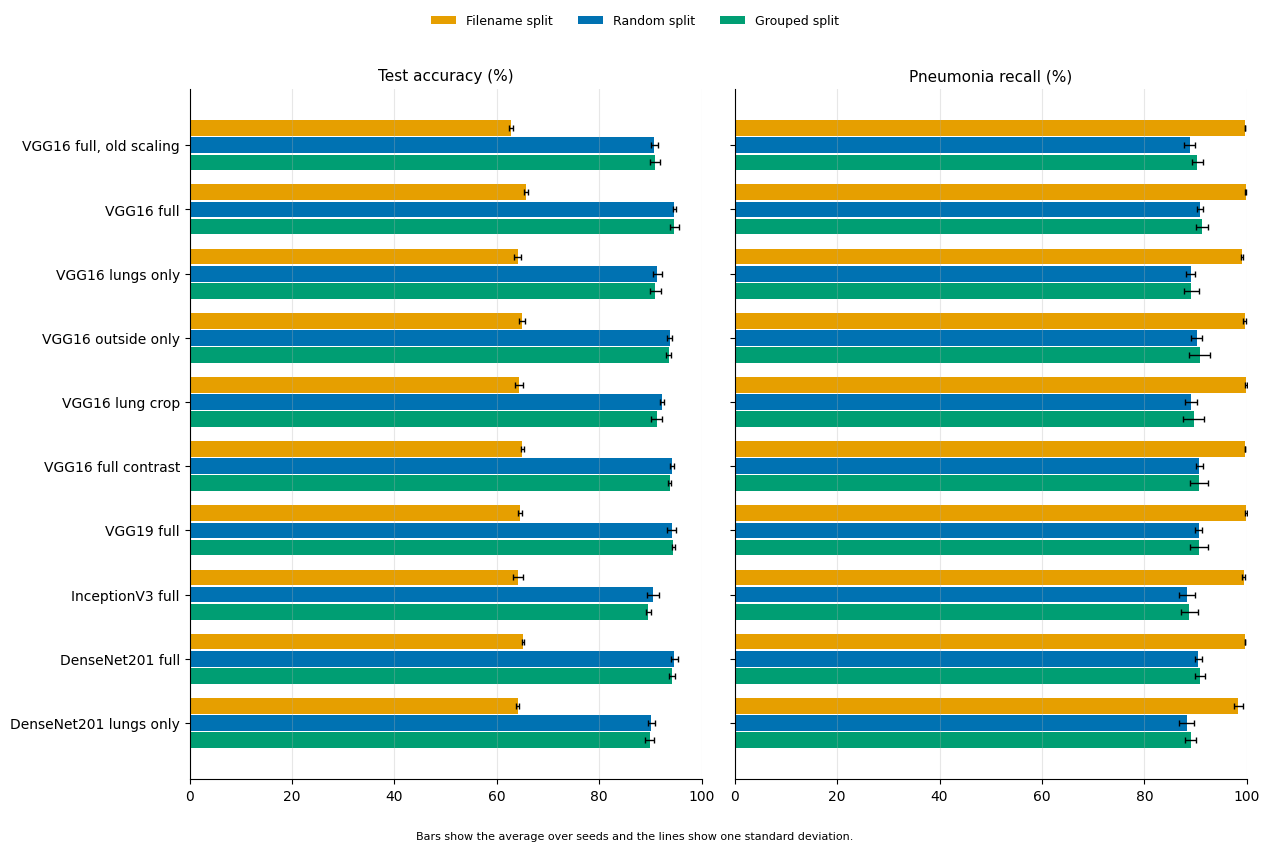

Change compared with VGG16 full, in percentage points. Same split and seed, so the comparison is paired.


,Random split mean difference,Random split better in seeds,Grouped split mean difference,Grouped split better in seeds
variant,,,,
"VGG16 full, old scaling",-3.9,0 of 5,-3.8,0 of 5
VGG16 lungs only,-3.3,0 of 5,-3.7,0 of 5
VGG16 outside only,-0.9,0 of 5,-1.1,0 of 5
VGG16 lung crop,-2.4,0 of 5,-3.5,0 of 5
VGG16 full contrast,-0.4,1 of 5,-0.9,1 of 5
VGG19 full,-0.5,1 of 5,-0.2,2 of 5
InceptionV3 full,-4.1,0 of 5,-5.1,0 of 5
DenseNet201 full,-0.0,2 of 5,-0.5,2 of 5
DenseNet201 lungs only,-4.5,0 of 5,-4.8,0 of 5


Highest average test accuracy on the grouped split: VGG16 full with 94.7 percent.
Against VGG16 full, old scaling (90.9 percent) it was better in 5 of 5 seeds, by 3.8 points on average.


In [17]:
fl.plot_grid(grid)
print("Change compared with VGG16 full, in percentage points. Same split and seed, so the comparison is paired.")
display(fl.paired_vs_baseline(grid, "test_acc").style.format({
    "Random split mean difference": "{:+.1f}", "Grouped split mean difference": "{:+.1f}"}))
fl.headline(grid, "grouped")

**Why the three class numbers mislead.** The first table splits recall by collection (grouped split, all seeds pooled). The second is a tree that only sees size, file type, file weight and brightness. The third shows which file clue separates covid from normal on 1024 by 1024 images. The fourth asks whether the picture alone, after resizing, reveals the collection inside one class.

In [18]:
psr, psr_n = fl.per_source_recall(lab, preds, seeds=SEEDS)
display(psr.style.format("{:.0%}"))
print("Test images behind each column, per seed:", psr_n)
print()
print("A tree that never sees the picture (three classes):")
fb = fl.format_baseline(lab, SEEDS)
display(fb)
print("Covid against normal on 1024 by 1024 images, one kind of file clue at a time:")
display(fl.cue_ablation(lab, SEEDS))
print("Inside one class, can the picture tell the two collections apart?")
display(fl.source_from_pixels(lab, seeds=SEEDS))

,"normal recall, PNG 1024 by 1024","normal recall, JPEG other sizes","pneumonia recall, PNG 1024 by 1024","pneumonia recall, JPEG other sizes",covid recall
variant,,,,,
"VGG16 full, old scaling",93%,73%,1%,98%,93%
VGG16 full,97%,88%,3%,99%,97%
VGG16 lungs only,93%,83%,2%,97%,92%
VGG16 outside only,97%,87%,1%,98%,94%
VGG16 lung crop,94%,72%,3%,97%,93%
VGG16 full contrast,97%,88%,1%,98%,95%
VGG19 full,97%,93%,0%,99%,96%
InceptionV3 full,93%,80%,0%,96%,89%
DenseNet201 full,96%,88%,3%,98%,96%


Test images behind each column, per seed: {'normal test images, PNG 1024 by 1024': 295, 'normal test images, JPEG other sizes': 49, 'pneumonia test images, PNG 1024 by 1024': 27, 'pneumonia test images, JPEG other sizes': 320, 'covid test images': 346}

A tree that never sees the picture (three classes):


,Test accuracy,Pneumonia recall
split,,
Grouped split,94.7 ± 0.4,90.4 ± 0.7
Random split,95.1 ± 0.4,90.8 ± 0.6


Covid against normal on 1024 by 1024 images, one kind of file clue at a time:


,AUC
clue,
File type only,0.999 ± 0.002
File weight only,0.978 ± 0.009
Brightness only (average and spread of gray),0.870 ± 0.021


Inside one class, can the picture tell the two collections apart?


,images PNG 1024 by 1024,images JPEG other sizes,AUC for telling the two collections apart
class,,,
normal,1977,336,0.999 ± 0.001
pneumonia,176,2137,1.000 ± 0.000


## Experiment 2: normal against pneumonia, fairly

Inside one collection, both classes come from the same place. Across collections, the model learns in one place and is tested in the other. Classes are balanced by repeating images, groups stay together, and the scores are AUC and average recall. The last row is a tree on size, file weight and brightness, which checks for leftover file clues inside a collection. Our guess is 10 to 15 minutes.

In [19]:
st = fl.source_tests(lab, seeds=SOURCE_SEEDS)
print("Images in each test (first seed):")
for k, v in st.attrs["counts"].items():
    print(" ", k, v)

  Within PNG 1024 by 1024: done, 170 seconds so far
  Within JPEG other sizes: done, 347 seconds so far
  Train JPEG other sizes, test PNG 1024 by 1024: done, 568 seconds so far
  Train PNG 1024 by 1024, test JPEG other sizes: done, 779 seconds so far
Images in each test (first seed):
  Within PNG 1024 by 1024 {'train normal': 1290, 'train pneumonia': 111, 'test normal': 293, 'test pneumonia': 29}
  Within JPEG other sizes {'train normal': 219, 'train pneumonia': 1390, 'test normal': 50, 'test pneumonia': 320}
  Train JPEG other sizes, test PNG 1024 by 1024 {'train normal': 269, 'train pneumonia': 1710, 'test normal': 1977, 'test pneumonia': 176}
  Train PNG 1024 by 1024, test JPEG other sizes {'train normal': 1585, 'train pneumonia': 138, 'test normal': 336, 'test pneumonia': 2137}


AUC, average and spread over seeds:


task,Within PNG 1024 by 1024,Within JPEG other sizes,"Train JPEG other sizes, test PNG 1024 by 1024","Train PNG 1024 by 1024, test JPEG other sizes"
inputs,,,,
"VGG16 full, old scaling",0.691 ± 0.039,0.990 ± 0.005,0.552 ± 0.005,0.561 ± 0.151
VGG16 full,0.698 ± 0.030,0.994 ± 0.005,0.539 ± 0.008,0.452 ± 0.109
VGG16 lungs only,0.679 ± 0.046,0.987 ± 0.009,0.506 ± 0.024,0.419 ± 0.068
VGG16 outside only,0.690 ± 0.045,0.994 ± 0.003,0.434 ± 0.016,0.356 ± 0.063
VGG16 lung crop,0.682 ± 0.056,0.968 ± 0.018,0.536 ± 0.013,0.521 ± 0.091
VGG16 full contrast,0.656 ± 0.068,0.992 ± 0.005,0.522 ± 0.011,0.420 ± 0.106
VGG19 full,0.679 ± 0.054,0.995 ± 0.003,0.504 ± 0.017,0.487 ± 0.100
InceptionV3 full,0.678 ± 0.069,0.980 ± 0.014,0.510 ± 0.012,0.451 ± 0.077
DenseNet201 full,0.751 ± 0.027,0.995 ± 0.002,0.509 ± 0.017,0.265 ± 0.044


Average recall in percent:


task,Within PNG 1024 by 1024,Within JPEG other sizes,"Train JPEG other sizes, test PNG 1024 by 1024","Train PNG 1024 by 1024, test JPEG other sizes"
inputs,,,,
"VGG16 full, old scaling",62.9 ± 3.1,94.7 ± 2.1,51.3 ± 0.8,55.5 ± 6.6
VGG16 full,63.0 ± 3.0,95.5 ± 2.7,51.5 ± 0.9,47.5 ± 6.0
VGG16 lungs only,63.8 ± 3.7,93.6 ± 2.2,50.9 ± 1.3,45.1 ± 4.5
VGG16 outside only,62.9 ± 4.0,95.3 ± 1.7,47.2 ± 1.8,40.3 ± 4.8
VGG16 lung crop,62.9 ± 5.3,91.3 ± 2.3,51.1 ± 1.2,52.4 ± 5.2
VGG16 full contrast,57.7 ± 5.5,94.3 ± 2.4,50.3 ± 1.1,46.1 ± 6.2
VGG19 full,61.8 ± 4.7,95.8 ± 2.0,49.5 ± 1.2,50.5 ± 4.2
InceptionV3 full,62.8 ± 4.8,92.9 ± 3.2,50.1 ± 1.0,46.7 ± 5.2
DenseNet201 full,67.9 ± 4.3,95.5 ± 2.9,50.4 ± 1.3,36.1 ± 6.1


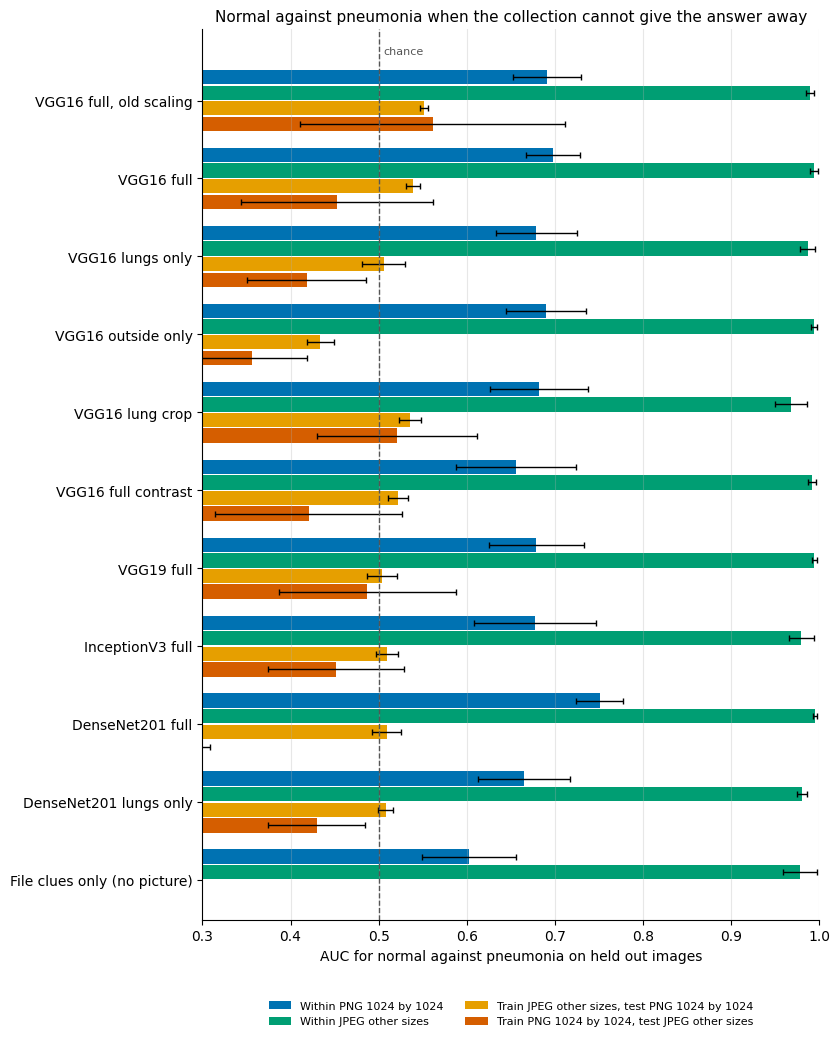

In [20]:
print("AUC, average and spread over seeds:")
display(fl.source_tests_table(st, "auc"))
print("Average recall in percent:")
display(fl.source_tests_table(st, "balanced"))
fl.plot_source_tests(st)

## Experiment 3: where does the model look?

Heatmaps from VGG16 for held out images. White outlines show the lungs. Green titles are correct and red titles are wrong.

Largest difference between the heatmap model and the fast head on 6 images: 1.04e-07


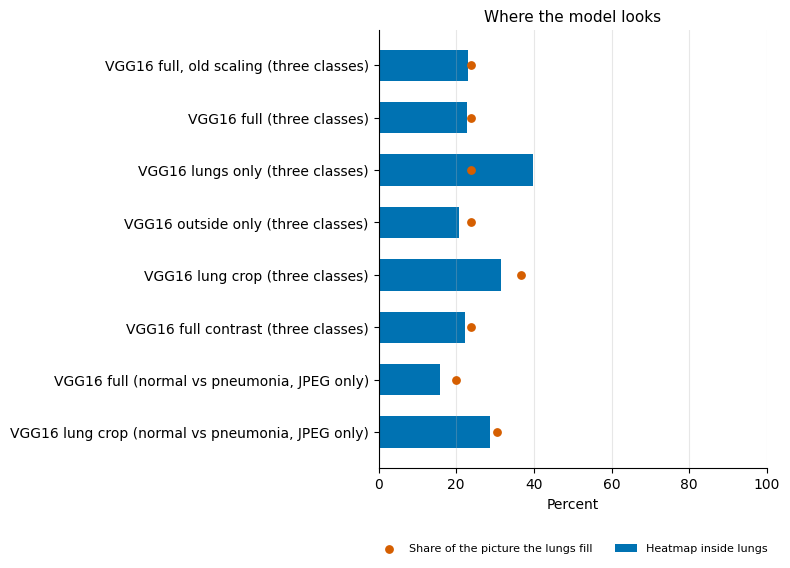

In [21]:
fl.check_transfer(lab, states)
te = lab.splits[("grouped", 0)][2]
idx3, y3 = fl.pick_per_class(te, lab.labels[te], 40)
vgg = [v for v in fl.order_of(states) if fl.VARIANTS[v]["net"] == "vgg16"]
att3, built, store3 = fl.attention_for(lab, states, vgg, idx3, y3, lab.classes, model_label="three classes")

kept = st.attrs["kept"]
task = fl.TASKS[1]
fair_states = {v: kept[(task, v)][0] for v in ("VGG16 full", "VGG16 lung crop")}
test_pos, test_y = kept[(task, "VGG16 full")][1], kept[(task, "VGG16 full")][2]
idx2, y2 = fl.pick_per_class(test_pos, test_y, 40)
att2, built, store2 = fl.attention_for(lab, fair_states, list(fair_states), idx2, y2, ["normal", "pneumonia"], built,
                                       model_label="normal vs pneumonia, JPEG only")
att_tab = fl.attention_table(pd.concat([att3, att2]))
display(att_tab.style.format({"Lungs fill": "{:.0%}", "Heatmap inside lungs": "{:.0%}", "Ratio": "{:.2f}"}))
fl.plot_attention(att_tab)

Three class model


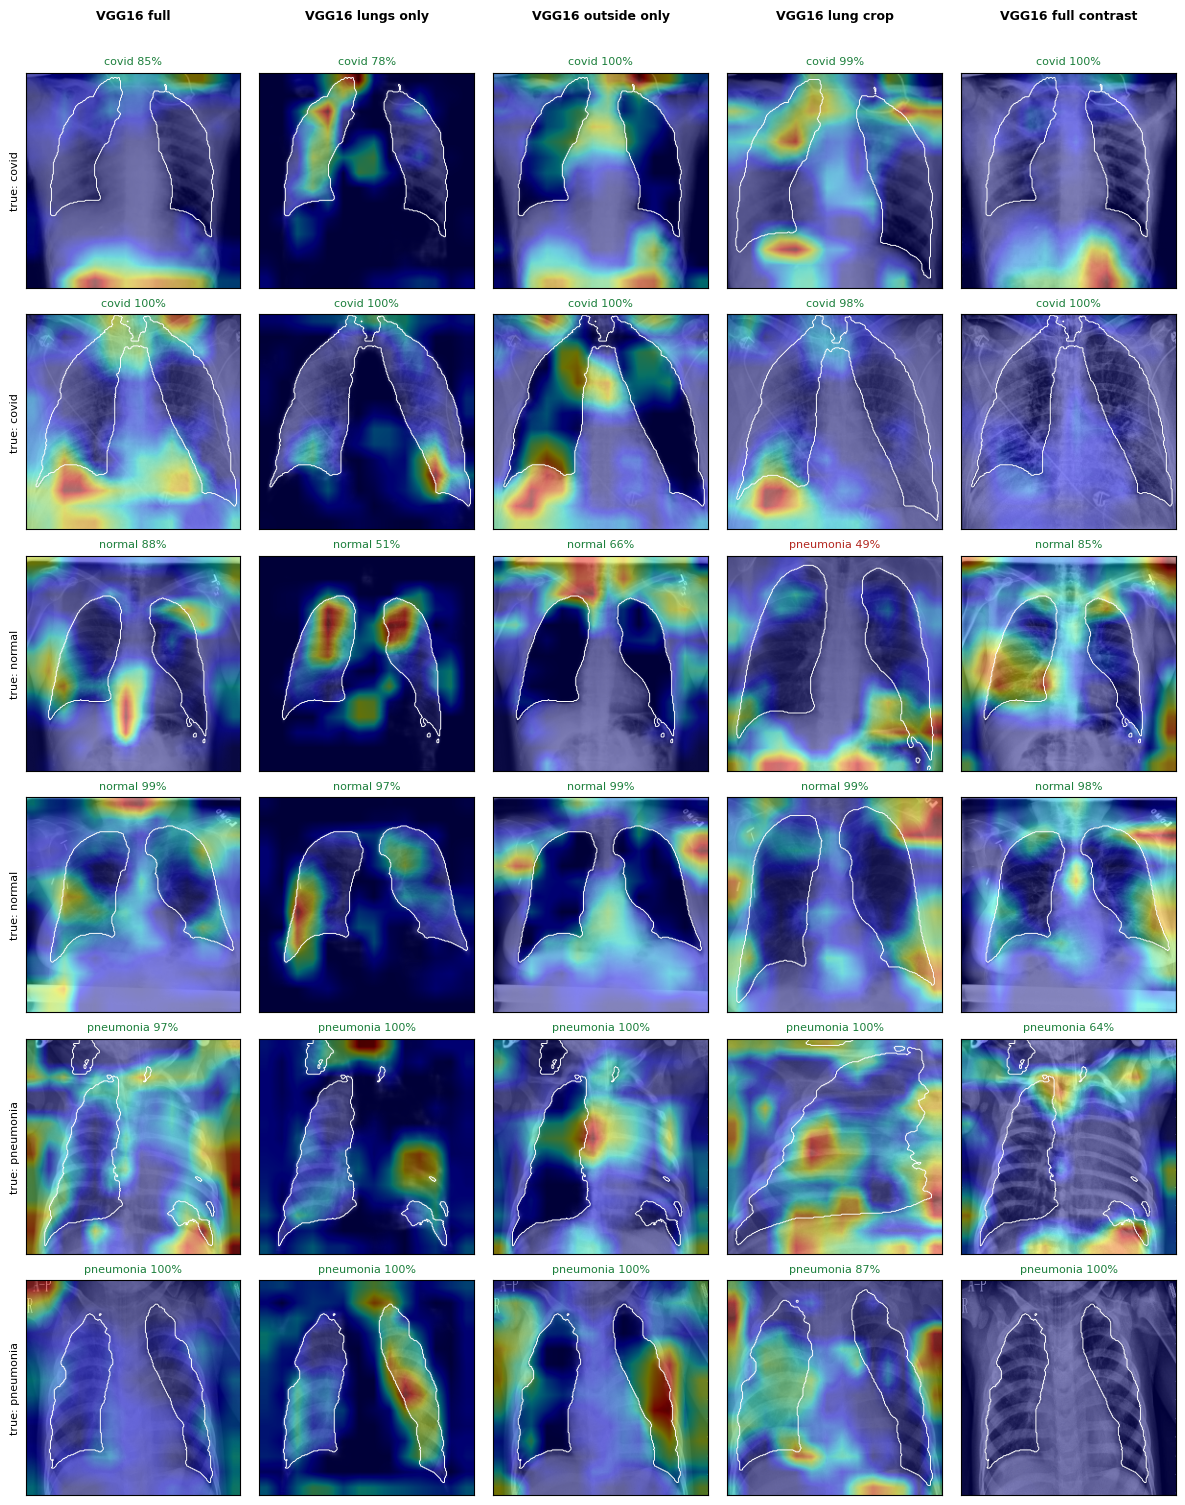

Normal against pneumonia, trained and tested inside the JPEG collection


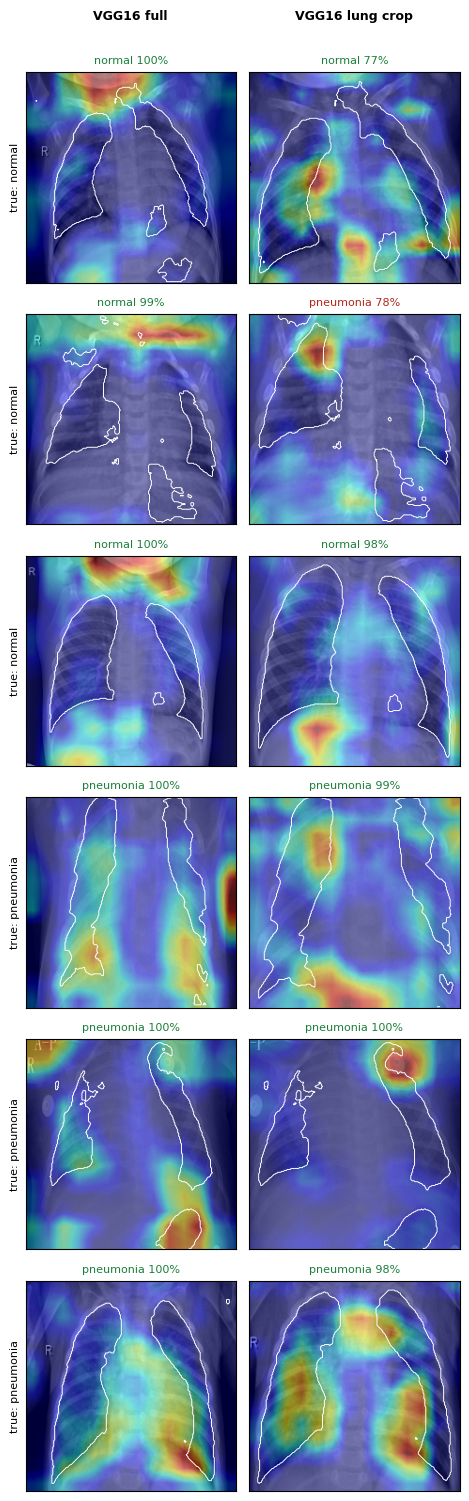

In [22]:
fl.heatmap_gallery(built, store3, idx3, y3, lab.classes,
                   ["VGG16 full", "VGG16 lungs only", "VGG16 outside only", "VGG16 lung crop", "VGG16 full contrast"],
                   n_per_class=2, title="Three class model")
fl.heatmap_gallery(built, store2, idx2, y2, ["normal", "pneumonia"], list(fair_states),
                   n_per_class=3, title="Normal against pneumonia, trained and tested inside the JPEG collection")

## Everything in one table, and the numbers for the slides

In [23]:
display(fl.final_table(grid, st))
print()
fl.key_numbers(grid, st, fb, psr, att_tab)

,"Three classes, grouped split, accuracy",AUC within png 1024 by 1024,AUC within jpeg other sizes,"AUC train jpeg other sizes, test png 1024 by 1024","AUC train png 1024 by 1024, test jpeg other sizes"
Version,,,,,
"VGG16 full, old scaling",90.9 ± 1.1,0.691 ± 0.039,0.990 ± 0.005,0.552 ± 0.005,0.561 ± 0.151
VGG16 full,94.7 ± 0.8,0.698 ± 0.030,0.994 ± 0.005,0.539 ± 0.008,0.452 ± 0.109
VGG16 lungs only,90.9 ± 1.0,0.679 ± 0.046,0.987 ± 0.009,0.506 ± 0.024,0.419 ± 0.068
VGG16 outside only,93.5 ± 0.6,0.690 ± 0.045,0.994 ± 0.003,0.434 ± 0.016,0.356 ± 0.063
VGG16 lung crop,91.2 ± 1.0,0.682 ± 0.056,0.968 ± 0.018,0.536 ± 0.013,0.521 ± 0.091
VGG16 full contrast,93.7 ± 0.4,0.656 ± 0.068,0.992 ± 0.005,0.522 ± 0.011,0.420 ± 0.106
VGG19 full,94.4 ± 0.3,0.679 ± 0.054,0.995 ± 0.003,0.504 ± 0.017,0.487 ± 0.100
InceptionV3 full,89.5 ± 0.5,0.678 ± 0.069,0.980 ± 0.014,0.510 ± 0.012,0.451 ± 0.077
DenseNet201 full,94.2 ± 0.5,0.751 ± 0.027,0.995 ± 0.002,0.509 ± 0.017,0.265 ± 0.044



1. A tree that never sees the picture gets 94.7 percent on the three class grouped split.
2. The best network version, VGG16 full, gets 94.7 percent on the same split.
3. Using the scaling VGG16 was trained with changes accuracy by +3.8 points (5 of 5 seeds better).
4. VGG16 full finds 3% of pneumonia images that come from the PNG collection, and calls 88% of normal images from the JPEG collection normal.
5. Within PNG 1024 by 1024: AUC ranges from 0.656 to 0.751 across versions, best is DenseNet201 full, and file clues alone reach 0.603.
5. Within JPEG other sizes: AUC ranges from 0.968 to 0.995 across versions, best is DenseNet201 full, and file clues alone reach 0.978.
5. Train JPEG other sizes, test PNG 1024 by 1024: AUC ranges from 0.434 to 0.552 across versions, best is VGG16 full, old scaling.
5. Train PNG 1024 by 1024, test JPEG other sizes: AUC ranges from 0.265 to 0.561 across versions, best is VGG16 full, old scaling.
6. Heatmap of VGG16 full (three classes): 23% inside the